# In-class work 7. Neural networks: tables, rewards, signals and sequences

Industrial AI, KBTU. Goes with Lectures 6 and 7. One notebook for both class hours
of the week.

| hour | parts | data |
|---|---|---|
| 1 | 1–6 an MLP in PyTorch, from one neuron to early stopping and seeds; 7 Q-learning; 8 why the table works; 9 where to find papers | AI4I 2020, a simulated room |
| 2 | 10 cleaning a log; 11 sliding windows; 12 an autoencoder; 13 the Fourier transform; 14 a CNN; 15 an LSTM; 16 attention | simulated logs and signals, pump sensor |

Parts 1–6 ask the question of In-class works 4 and 5, *will this AI4I cycle end in a failure?*,
on the split of In-class work 5. Run top to bottom with `Shift+Enter`, about five minutes.

The networks train on a GPU if PyTorch finds one (`DEVICE`, set in the first cell that uses
PyTorch) and on the CPU otherwise. A GPU computes in a different order, so a training run can end
a few digits, or a few epochs, away from the numbers quoted in the text.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

import sklearn
import torch
from torch import nn

BLUE, ORANGE, RED, GREEN, PURPLE, GREY = (
    "#2a6f8e", "#e07b39", "#c0392b", "#4a8f5a", "#9b3f9b", "#9aa0a6")

mpl.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#cccccc",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e6e6",
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 10,
    "font.size": 10,
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "legend.frameon": False,
    "lines.linewidth": 1.6,
})

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

KAGGLE = {
    'ai4i': 'stephanmatzka/predictive-maintenance-dataset-ai4i-2020',
    'pump_sensor': 'nphantawee/pump-sensor-data',
}


def dataset_folder(name):
    """The folder with the files of a data set: the Kaggle copy (downloaded once, then cached),
    or data/<name>/ of the course repo if Kaggle is out of reach."""
    if KAGGLE[name]:
        try:
            import contextlib, io, logging, kagglehub
            logging.getLogger("kagglehub").setLevel(logging.ERROR)
            with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
                folder = Path(kagglehub.dataset_download(KAGGLE[name]))
            print(f"{name}: Kaggle {KAGGLE[name]}")
            return folder
        except Exception as exc:
            print(f"Kaggle unavailable ({type(exc).__name__}), looking for data/{name}/")
    for root in [Path.cwd(), *Path.cwd().parents]:
        if (root / "data" / name).is_dir():
            return root / "data" / name
    raise FileNotFoundError(f"no data/{name}/ here or above; run data/fetch.py in the course repo")

print(" | ".join(f"{m} {sys.modules[m].__version__}" for m in
                 ("numpy", "pandas", "matplotlib", "scipy", "sklearn", "torch") if m in sys.modules))

numpy 2.5.5 | pandas 3.1.1 | matplotlib 3.11.2 | scipy 1.18.1 | sklearn 1.9.1 | torch 2.8.0+cu128


In [3]:
STRAIN_LIMIT = {"L": 11_000, "M": 12_000, "H": 13_000}       # min*N*m, by product type


def load_ai4i():
    df = pd.read_csv(dataset_folder("ai4i") / "ai4i2020.csv", encoding="utf-8-sig")
    return df.rename(columns={
        "Product ID": "product", "Type": "type",
        "Air temperature [K]": "air", "Process temperature [K]": "process",
        "Rotational speed [rpm]": "rpm", "Torque [Nm]": "torque",
        "Tool wear [min]": "wear", "Machine failure": "failure"})


def physics(d):
    """The five physical quantities of In-class work 4, from the raw readings."""
    out = pd.DataFrame(index=d.index)
    out["dT"] = d["process"] - d["air"]                                    # K
    out["rpm"] = d["rpm"]
    out["power"] = d["torque"] * d["rpm"] * 2 * np.pi / 60                 # W
    limit = d["type"].map(STRAIN_LIMIT)
    out["strain_ratio"] = d["wear"] * d["torque"] / limit                # 1.0 = the limit
    out["wear"] = d["wear"]                                                # min
    return out


df = load_ai4i()
P = physics(df)
y = df["failure"].to_numpy()
print(df.shape, "| failures:", y.sum(), f"({y.mean():.1%})")
P.head(3)

ai4i: Kaggle stephanmatzka/predictive-maintenance-dataset-ai4i-2020
(10000, 14) | failures: 339 (3.4%)


,dT,rpm,power,strain_ratio,wear
0,10.500,1551,"6,951.591",0.000,0
1,10.500,1408,"6,826.723",0.013,3
2,10.400,1498,"7,749.388",0.022,5


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# a GPU if PyTorch finds one
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("training on", DEVICE)

# the split of In-class work 5: 60 / 20 / 20, the same failure rate in each part
idx = np.arange(len(df))
tr, rest = train_test_split(idx, test_size=0.4, stratify=y, random_state=0)
va, te = train_test_split(rest, test_size=0.5, stratify=y[rest], random_state=0)

scaler = StandardScaler().fit(P.iloc[tr])                   # fitted on train only
Z = scaler.transform(P).astype(np.float32)
Xtr, Xva, Xte = (torch.tensor(Z[i]).to(DEVICE) for i in (tr, va, te))
ytr, yva, yte = (torch.tensor(y[i], dtype=torch.float32).to(DEVICE) for i in (tr, va, te))
print("train", tuple(Xtr.shape), "| validation", tuple(Xva.shape),
      "| test", tuple(Xte.shape))
print(Xtr[:3])
print(ytr[:10])

training on cuda
train (6000, 5) | validation (2000, 5) | test (2000, 5)


tensor([[ 1.2911,  1.5274, -1.7758, -0.9146, -0.5735],
        [ 1.5908, -0.5151,  0.9441, -1.3764, -1.5445],
        [ 1.2911,  0.7907, -0.7552, -0.3669,  0.1782]], device='cuda:0')
tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], device='cuda:0')


A **tensor** is PyTorch's array. The five scaled physical quantities of 6000 training cycles
form one tensor of 6000 × 5 numbers. PyTorch wants `float32`, and for a yes/no task it wants the
labels as floats too.

---

# Part 1. One neuron is a logistic regression

A neuron multiplies each input by a weight, adds a bias and passes the sum through an
activation. With the five inputs of a cycle in a vector $\mathbf{x} \in \mathbb{R}^5$:

$$z = \mathbf{w}^\top \mathbf{x} + b, \qquad p = \sigma(z) = \frac{1}{1 + e^{-z}}$$

With the sigmoid $\sigma$ as the activation this is exactly the logistic regression of
In-class work 5. Training minimises the **binary cross-entropy**, the same log-loss:

$$L(\mathbf{w}, b) = -\frac{1}{n}\sum_i \big[\, y_i \log p_i + (1 - y_i) \log(1 - p_i) \,\big]$$

Its gradient is short: $\partial L / \partial \mathbf{w} = \frac{1}{n}\sum_i (p_i - y_i)\,\mathbf{x}_i$.
Each cycle pushes the weights along its own $\mathbf{x}_i$, as hard as its prediction is wrong.

In PyTorch `nn.Linear(5, 1)` is the weighted sum, and `nn.BCEWithLogitsLoss()` applies the
sigmoid and the loss in one step, which is numerically safer than doing them separately. Every
training step is the same four lines.

In [5]:
from sklearn.linear_model import LogisticRegression

torch.manual_seed(0)
neuron = nn.Linear(5, 1).to(DEVICE)     # five weights and one bias, random at the start
loss_fn = nn.BCEWithLogitsLoss()
opt = torch.optim.Adam(neuron.parameters(), lr=0.05)

for step in range(1500):
    opt.zero_grad()                             # 1. forget the gradients of the last step
    logits = neuron(Xtr).squeeze(1)             # 2. forward: outputs and their loss
    loss = loss_fn(logits, ytr)
    loss.backward()                             # 3. backward: d loss / d every weight
    opt.step()                                  # 4. move every weight a little downhill
    if step in (0, 10, 100, 1499):
        print(f"step {step:4d}  loss {loss.item():.4f}")

sk = LogisticRegression(C=np.inf, max_iter=5000).fit(Z[tr], y[tr])
neuron_weights = neuron.weight.detach().cpu().numpy()[0]
both = {"PyTorch neuron": neuron_weights, "scikit-learn": sk.coef_[0]}
weight_table = pd.DataFrame(both, index=P.columns).T
weight_table.assign(bias=[neuron.bias.item(), sk.intercept_[0]])

step    0  loss 0.8577
step   10  loss 0.5426
step  100  loss 0.1335


step 1499  loss 0.1053


,dT,rpm,power,strain_ratio,wear,bias
PyTorch neuron,-0.826,1.465,1.338,1.590,-1.009,-4.453
scikit-learn,-0.826,1.464,1.336,1.589,-1.008,-4.453


After 1500 steps the neuron's weights agree with scikit-learn's to the second or third decimal.
`C=np.inf` switches off scikit-learn's regularisation, so both minimise the same loss, and the
log-loss of a linear model is convex: it has one minimum, and any decent optimiser finds it. The
last small gap is there because Adam stops near the minimum. **The neuron is a logistic
regression**, trained by a different algorithm.

Read the signs with care. `wear` gets a negative weight only because `strain_ratio` already
contains the wear: two correlated inputs share one effect between them, as in In-class work 4.

---

# Part 2. What a hidden layer adds

In-class work 4 found the documented rule for power failures: the machine fails when the power
is **below about 3500 W or above about 9000 W**. Failures sit at both ends, with a safe band in
the middle. A neuron has one weight per input, so its score can only rise with the power or fall
with it. It cannot say "both ends".

A **hidden layer** puts several neurons side by side and feeds their outputs to one more neuron.
Between them sits a non-linear function, here **ReLU**, $\max(0, v)$. With one input $x$ and 16
hidden neurons the output before the sigmoid is

$$z(x) = \sum_{j=1}^{16} v_j \max(0,\; w_j x + b_j) + c$$

Each term is a hinge: flat on one side of $x = -b_j / w_j$, a straight line on the other. A sum
of hinges is a broken line with up to 16 kinks, and a broken line can go down and come back up.

To see it, give both models one input only: the power.

one neuron               train loss 0.1330 | validation loss 0.1369


16 hidden ReLU neurons   train loss 0.1000 | validation loss 0.0987


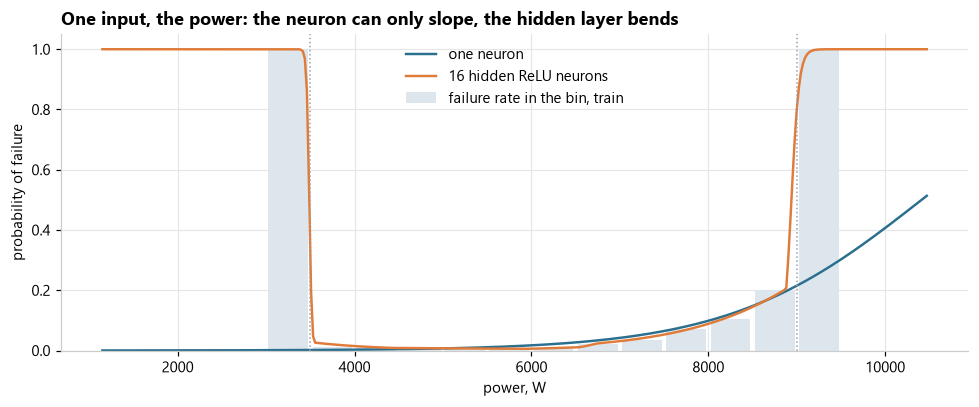

In [6]:
k = list(P.columns).index("power")
x1, x1_va = Xtr[:, [k]], Xva[:, [k]]

torch.manual_seed(0)
one_neuron = nn.Linear(1, 1).to(DEVICE)
hidden_layer = nn.Sequential(
    nn.Linear(1, 16),
    nn.ReLU(),
    nn.Linear(16, 1),
).to(DEVICE)
models = {"one neuron": one_neuron, "16 hidden ReLU neurons": hidden_layer}

for name, m in models.items():
    opt = torch.optim.Adam(m.parameters(), lr=0.02)
    for step in range(3000):
        opt.zero_grad()
        loss = loss_fn(m(x1).squeeze(1), ytr)
        loss.backward()
        opt.step()
    with torch.no_grad():
        va_loss = loss_fn(m(x1_va).squeeze(1), yva).item()
    print(f"{name:24s} train loss {loss.item():.4f} | validation loss {va_loss:.4f}")

# the failure rate of the train part in 500 W bins, bins with at least 10 cycles
watts = P["power"].to_numpy()
bins = np.arange(0, 14_001, 500)
bin_of = pd.cut(watts[tr], bins)
rate = pd.Series(y[tr]).groupby(bin_of, observed=True).agg(["mean", "size"])
rate = rate[rate["size"] >= 10]

# the power axis, scaled the way the networks saw it
grid = np.linspace(watts.min(), watts.max(), 400)
grid_z = (grid[:, None] - scaler.mean_[k]) / scaler.scale_[k]
grid_scaled = torch.tensor(grid_z, dtype=torch.float32).to(DEVICE)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar([b.mid for b in rate.index], rate["mean"], width=450, color="#dde6ec",
       label="failure rate in the bin, train")
for (name, m), c in zip(models.items(), [BLUE, ORANGE]):
    with torch.no_grad():
        prob = torch.sigmoid(m(grid_scaled)).squeeze(1).cpu().numpy()
    ax.plot(grid, prob, color=c, label=name)
for w in (3500, 9000):
    ax.axvline(w, color=GREY, ls=":", lw=1)
ax.set(xlabel="power, W", ylabel="probability of failure",
       title="One input, the power: the neuron can only slope, the hidden layer bends")
ax.legend(loc="upper center")
fig.tight_layout()
plt.show()

The bars are the failure rate in 500 W bins of the train part: 1.0 just below 3500 W, 1.0
above 9000 W, a few percent in between (the other failure modes).

The neuron draws one sigmoid. It rises slowly with the power and reaches 0.5 only past
10 000 W; below 3500 W it says zero, so every low-power failure is missed. The network with 16
hidden neurons puts both walls at the documented thresholds. Its validation loss is about
0.10 against 0.14.

Nobody told the network that there are two walls or where they stand. The kinks moved to where
the data needed them, because the gradient moves every $b_j$ and $w_j$ too. In-class work 4 got
the same walls from a decision tree, which draws steps; the network draws smooth bends.

---

# Part 3. The training loop

## 3.1 Mini-batches and epochs

So far every step looked at all 6000 training cycles. Real networks train on **mini-batches**:
take 128 cycles at random, make one step, take the next 128, and so on. One pass over the whole
train part is an **epoch**, here 47 steps. The gradient of a batch is an unbiased estimate of
the full gradient, with noise that shrinks like $1/\sqrt{128}$. Each step costs a fraction of a
full one, and the noise helps the weights out of flat, poor regions more than it hurts.

`DataLoader` cuts the tensors into shuffled batches. The `generator` with a seed makes the
shuffling the same on every run.

## 3.2 The network

Five inputs, two hidden layers of 64 ReLU neurons, one output:

$$\mathbf{h}_1 = \text{ReLU}(\mathbf{W}_1 \mathbf{x} + \mathbf{b}_1), \quad \mathbf{h}_2 = \text{ReLU}(\mathbf{W}_2 \mathbf{h}_1 + \mathbf{b}_2), \quad z = \mathbf{w}_3^\top \mathbf{h}_2 + b_3, \quad p = \sigma(z)$$

with $\mathbf{W}_1 \in \mathbb{R}^{64 \times 5}$, $\mathbf{W}_2 \in \mathbb{R}^{64 \times 64}$,
$\mathbf{w}_3 \in \mathbb{R}^{64}$. That is $5 \cdot 64 + 64 + 64 \cdot 64 + 64 + 64 + 1 = 4609$
weights. The function below builds the network, trains it, and after every epoch writes down
the loss on the train part and on the validation part. Those two lists are the **learning
curves**. The `patience` argument is for Part 4; for now it is off.

No class weights: In-class work 5 showed that `class_weight="balanced"` breaks the
probabilities, and we want to read the output as a probability again.

In [7]:
import copy
from torch.utils.data import TensorDataset, DataLoader


def make_net(hidden, seed):
    torch.manual_seed(seed)             # the same starting weights for the same seed
    layers = []
    n = Xtr.shape[1]
    for h in hidden:
        layers += [nn.Linear(n, h), nn.ReLU()]
        n = h
    return nn.Sequential(*layers, nn.Linear(n, 1)).to(DEVICE)


@torch.no_grad()
def loss_on(net, X, yt):
    net.eval()
    return loss_fn(net(X).squeeze(1), yt).item()


def train(hidden, epochs, seed=0, patience=None, batch=128, lr=1e-3):
    # returns the network, the learning curves (one row per epoch) and the epoch with the
    # lowest validation loss; with a patience, training stops early and the best weights
    # come back
    net = make_net(hidden, seed)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    shuffle_rng = torch.Generator().manual_seed(seed)
    loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=batch, shuffle=True,
                        generator=shuffle_rng)

    hist = []
    best_loss = np.inf
    best_state = None
    best_epoch = -1
    for epoch in range(epochs):
        net.train()
        for xb, yb in loader:                 # the same four lines, once per batch
            opt.zero_grad()
            loss = loss_fn(net(xb).squeeze(1), yb)
            loss.backward()
            opt.step()

        tr_loss = loss_on(net, Xtr, ytr)
        va_loss = loss_on(net, Xva, yva)
        hist.append((tr_loss, va_loss))
        if va_loss < best_loss:               # remember the best epoch on validation
            best_loss = va_loss
            best_state = copy.deepcopy(net.state_dict())
            best_epoch = epoch
        if patience is not None and epoch - best_epoch >= patience:
            break
    if patience is not None:
        net.load_state_dict(best_state)       # early stopping: go back to the best epoch
    return net, pd.DataFrame(hist, columns=["train", "validation"]), best_epoch


print(make_net([64, 64], seed=0))

Sequential(
  (0): Linear(in_features=5, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=1, bias=True)
)


200 epochs in 29 s


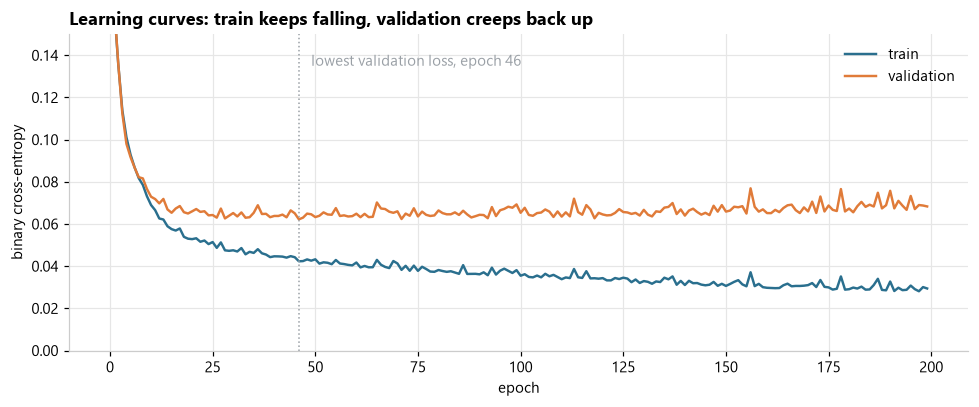

     train  validation
0    0.203       0.205
10   0.069       0.073
46   0.042       0.062
100  0.035       0.065
150  0.031       0.066
199  0.029       0.068


In [8]:
import time

t0 = time.perf_counter()
net_long, hist, best = train([64, 64], epochs=200)
print(f"200 epochs in {time.perf_counter() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(hist["train"], color=BLUE, label="train")
ax.plot(hist["validation"], color=ORANGE, label="validation")
ax.axvline(best, color=GREY, ls=":", lw=1)
ax.text(best + 3, 0.135, f"lowest validation loss, epoch {best}", color=GREY)
ax.set(xlabel="epoch", ylabel="binary cross-entropy", ylim=(0, 0.15),
       title="Learning curves: train keeps falling, validation creeps back up")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()
print(hist.loc[[0, 10, best, 100, 150, 199]].round(4).to_string())

There are three stages.

- In epochs 0–10 both losses fall fast and together. The network learns what holds for all
  cycles.
- Up to about epoch 46 the validation loss still falls, more slowly, and reaches its minimum,
  about 0.062.
- After that the train loss keeps falling (about 0.04 at the best epoch, 0.03 at epoch 199)
  while the validation loss creeps back up to about 0.07. The network now learns these particular 6000 cycles,
  noise included. It has 4609 weights to do it with and only 203 failures to learn from. This
  is **overfitting**, and the gap between the two curves measures it.

The train loss is measured on the data the gradient sees, so it can only keep improving. The
validation loss is an estimate of the loss on new cycles, and only that curve says when to stop.

---

# Part 4. Early stopping

The cure is in the curve itself: watch the validation loss after every epoch, remember the
weights of the best epoch, and stop when it has not improved for `patience` epochs. Then put the
remembered weights back.

Two details matter.

- The weights must be **copied** (`copy.deepcopy(net.state_dict())`). `state_dict()` returns the
  live tensors that keep training, so without a copy the "best" weights are the last ones.
- The epoch is chosen on the **validation** part. That makes validation a part of training, and
  the final measurement goes to the test part, as in In-class work 5.

In [9]:
# 300 epochs is only the upper limit now
net, hist_es, best_es = train([64, 64], epochs=300, patience=20)
long_run_end = hist["validation"].iloc[-1]
print(f"stopped after epoch {len(hist_es) - 1}, best epoch {best_es}, "
      f"validation loss {loss_on(net, Xva, yva):.4f}  "
      f"(the long run ended at {long_run_end:.4f})")

stopped after epoch 66, best epoch 46, validation loss 0.0622  (the long run ended at 0.0683)


In our run training stopped at epoch 66, twenty epochs after the best one, and the weights of
epoch 46 were put back: validation loss about 0.062, against about 0.07 at the end of the long
run.

`patience` is a trade-off. The validation curve is noisy (look at the spikes in Part 3), so a
patience of 1 or 2 stops at the first bump, and a patience of 100 hardly ever stops.

---

# Part 5. The network against the baselines

Now the comparison with In-class work 5, on the same test cycles. Five models:

- logistic regression and the 300-tree forest on the **raw sensors**, exactly as in In-class
  work 5;
- logistic regression and the forest on the **five physical quantities**;
- the early-stopped network from Part 4, on the same five quantities.

For each we print the average precision on validation and test, ROC-AUC on test, and the cost
of In-class work 5 ($C_{FP} = 1$, $C_{FN} = 20$) on test at the threshold that was cheapest
**on validation**.

In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

C_FP, C_FN = 1, 20


def cost(yt, s, t):
    alarm = s >= t
    return C_FP * (alarm & (yt == 0)).sum() + C_FN * (~alarm & (yt == 1)).sum()


@torch.no_grad()
def score(net, X):
    net.eval()
    return torch.sigmoid(net(X)).squeeze(1).cpu().numpy()


def report(s_va, s_te):
    grid = np.linspace(0, 1, 201)
    t = grid[np.argmin([cost(y[va], s_va, g) for g in grid])]
    return {"AP validation": average_precision_score(y[va], s_va),
            "AP test": average_precision_score(y[te], s_te),
            "ROC-AUC test": roc_auc_score(y[te], s_te),
            "threshold": t,
            "cost test": cost(y[te], s_te, t)}


# the raw-sensor models of In-class work 5: one-hot product type, the rest as numbers
RAW = ["type", "air", "process", "rpm", "torque", "wear"]
TYPE = ["type"]
raw_scaled = make_column_transformer((OneHotEncoder(), TYPE), remainder=StandardScaler())
raw_as_is = make_column_transformer((OneHotEncoder(), TYPE), remainder="passthrough")
raw_lr = make_pipeline(raw_scaled, LogisticRegression(max_iter=2000))
raw_rf = make_pipeline(raw_as_is, RandomForestClassifier(300, random_state=0, n_jobs=-1))

results = {}          # model name -> its row; a dict, so re-running adds no rows
for name, m in [("logistic, raw sensors", raw_lr), ("forest, raw sensors", raw_rf)]:
    m.fit(df.iloc[tr][RAW], y[tr])
    s_va = m.predict_proba(df.iloc[va][RAW])[:, 1]
    s_te = m.predict_proba(df.iloc[te][RAW])[:, 1]
    results[name] = report(s_va, s_te)

physics_lr = LogisticRegression(max_iter=2000)
physics_rf = RandomForestClassifier(300, random_state=0, n_jobs=-1)
physics_models = [("logistic, physics", physics_lr), ("forest, physics", physics_rf)]
for name, m in physics_models:
    m.fit(Z[tr], y[tr])
    results[name] = report(m.predict_proba(Z[va])[:, 1], m.predict_proba(Z[te])[:, 1])
results["network [64, 64], physics"] = report(score(net, Xva), score(net, Xte))
results["never alarm"] = {"cost test": C_FN * y[te].sum()}
pd.DataFrame(results).T

,AP validation,AP test,ROC-AUC test,threshold,cost test
"logistic, raw sensors",0.502,0.385,0.859,0.100,747.000
"forest, raw sensors",0.667,0.810,0.967,0.070,266.000
"logistic, physics",0.389,0.364,0.818,0.055,771.000
"forest, physics",0.858,0.913,0.977,0.125,207.000
"network [64, 64], physics",0.732,0.798,0.977,0.045,269.000
never alarm,NaN,NaN,NaN,NaN,"1,360.000"


Read the table by rows.

- The network against the logistic regression on the same five quantities: AP about 0.8
  against 0.36 on test, cost about 270 against 771. That is Part 2 at full size. In-class work 4 saw the
  logistic regression get *worse* with physics features: one weight per input cannot hold the
  power band.
- The network against the forest of In-class work 5 (raw sensors): level. Cost about 270
  against 266, AP about 0.80 against 0.81.
- The forest on the same five quantities beats both: AP 0.91, cost 207. The AI4I failures are
  thresholds ("power below 3500 W"), and a forest is made of thresholds.
- The network's cheapest threshold on validation is about 0.045, next to $t^* = 1/21 = 0.048$ from
  In-class work 5. Trained on the log-loss without class weights, its outputs are close to
  honest probabilities.

On a table of a few good physical quantities a forest is hard to beat. Networks earn their keep
where nobody has computed the quantities yet: raw signals, images, sound, long sequences.
Practice 4 sits in between: vibration, turned into features by hand.

---

# Part 6. One network is one draw

The forest has a seed too, but its 300 trees average each other out. A network starts from
random weights and sees the batches in a random order, and its loss surface has many minima of
similar height. Change the seed and you get a different network. Five seeds, the same recipe:

In [11]:
by_seed = {}                     # seed -> its row
for seed in range(5):
    net_s, h_s, b_s = train([64, 64], epochs=300, seed=seed, patience=20)
    row = report(score(net_s, Xva), score(net_s, Xte))
    by_seed[f"seed {seed}"] = {**row, "best epoch": b_s}
seeds = pd.DataFrame(by_seed).T
print(seeds.round(3).to_string())

ap = seeds["AP test"]
cost_te = seeds["cost test"]
print(f"\nAP test from {ap.min():.3f} to {ap.max():.3f}; "
      f"cost test from {cost_te.min():.0f} to {cost_te.max():.0f}")

        AP validation  AP test  ROC-AUC test  threshold  cost test  best epoch
seed 0          0.732    0.798         0.977      0.045    269.000      46.000
seed 1          0.732    0.770         0.975      0.045    300.000      31.000
seed 2          0.711    0.708         0.968      0.045    357.000      19.000
seed 3          0.703    0.751         0.975      0.060    273.000      25.000
seed 4          0.746    0.773         0.974      0.045    337.000      33.000

AP test from 0.708 to 0.798; cost test from 269 to 357


Same data, same recipe, five seeds. In our run the test AP went from 0.71 to 0.80, the cost
from 269 to 357, the best epoch anywhere from 19 to 46. Seed 0, the network of Part 5, happens to be the best of the five.

There are two consequences.

1. One run of a network is one draw. Report the seed and the spread over seeds. In In-class
   work 5 the bootstrap gave the forest's AP an interval of 0.72–0.89 from the test sample
   alone. The seed adds a second source of noise on top of that.
2. Choosing the seed by its test result is choosing on the test set, the same mistake as
   choosing a threshold there. If you choose among seeds, choose on validation. Here validation
   would have picked seed 4 (AP 0.746), which costs 337 on test, not 269.

---

# Part 7. Learning from a reward instead of labels

Everything so far learned from **labels**: for every training cycle somebody wrote down whether
it failed. A controller has no such labels. Nobody can say what the right heater setting was at
03:15 last Tuesday; we only know afterwards whether the room was comfortable and how much energy
it took. **Reinforcement learning** (RL) learns from exactly that.

Lecture 6 named the parts. Here they are for a room with an electric heater:

| part | here |
|---|---|
| environment | the room: its heat capacity, its heat loss to the outside |
| agent | the controller we train |
| state | what the agent sees: the room temperature, rounded to 0.5 °C |
| action | the heater power: 0, 2 or 4 kW, chosen every 5 minutes |
| reward | a number after every step: minus the energy, minus a penalty for leaving 21 ± 0.5 °C, minus 10 for overheating above 25 °C |

The room is a first-order model, the same kind as a plant in a PID course:

$$T_{k+1} = T_k + \frac{\Delta t}{\tau}\Big(R\,P_k - \big(T_k - T_{out}(t_k)\big)\Big) + \text{noise}$$

with $\tau = 3$ h, $R = 7$ K/kW, $\Delta t = 5$ min. In a steady state $T = T_{out} + R P$, so
holding 21 °C needs $P = (21 - T_{out}) / 7$. Outside it is −4 °C at midnight and +8 °C at noon,
so the room needs between 1.9 and 3.6 kW. No single setting is right all day.

In [12]:
DT = 5 / 60                                    # hours per step
STEPS_PER_DAY = 288                            # 24 h of 5-minute steps
ACTIONS = np.array([0.0, 2.0, 4.0])            # heater power, kW
TAU = 3.0                                      # time constant of the room, h
R_ROOM = 7.0                                   # K of warming per kW
T_SET = 21.0                                   # set point, C


def t_out(k):
    # outside temperature at step k: -4 C at midnight, +8 C at noon
    hour = k * DT
    return 2 - 6 * np.cos(2 * np.pi * hour / 24)


def room_step(T, a, k, rng):
    heating = R_ROOM * ACTIONS[a]
    loss = T - t_out(k)
    noise = rng.normal(0, 0.05)
    return T + DT / TAU * (heating - loss) + noise


def reward(T_next, a):
    energy = ACTIONS[a] * DT                                  # kWh
    discomfort = max(0.0, abs(T_next - T_SET) - 0.5)          # K outside the band
    r = -energy - discomfort
    if T_next > 25:
        r -= 10                                               # overheating
    return r


T_BINS = np.arange(14, 28.01, 0.5)             # bin edges, C
N_STATES = len(T_BINS) + 1                     # one bin below 14 C and one above 28 C


def state(T):
    # the number of the 0.5 C bin the temperature falls into
    return int(np.digitize(T, T_BINS))


print(f"{N_STATES} temperature bins x {len(ACTIONS)} actions "
      f"= {N_STATES * len(ACTIONS)} numbers in the Q-table")

30 temperature bins x 3 actions = 90 numbers in the Q-table


**Q-learning** keeps a table $Q(s, a)$: how much reward the agent expects from now on if it
takes action $a$ in state $s$ and acts well afterwards. After every step it moves the table entry
a little towards what actually happened:

$$Q(s, a) \leftarrow Q(s, a) + \alpha\,\Big[\,r + \gamma \max_{a'} Q(s', a') - Q(s, a)\,\Big]$$

$r$ is the reward just received, $s'$ the new state, $\alpha = 0.1$ the step size, and
$\gamma = 0.95$ says how much the future counts. The bracket is the surprise: what this step
earned plus the best the table promises from the next state, minus what the table expected. When
the table is right the surprise averages to zero and the entries stop moving.

$\gamma$ sets the horizon. A reward $k$ steps ahead counts $\gamma^k$, and
$\sum_k \gamma^k = 1/(1-\gamma) = 20$, so the agent looks roughly 20 steps, 100 minutes, ahead.
That is long enough to see that switching the heater on now keeps the room in the band an hour
later.

To learn anything the agent must also try actions it does not yet think best. With probability
$\varepsilon$ it acts at random (**exploration**), otherwise it takes the best action in the
table. $\varepsilon$ starts at 1 and falls to 0.05 over the first 500 days. Training: 1000
simulated days, each from a random starting temperature. It takes a few seconds.

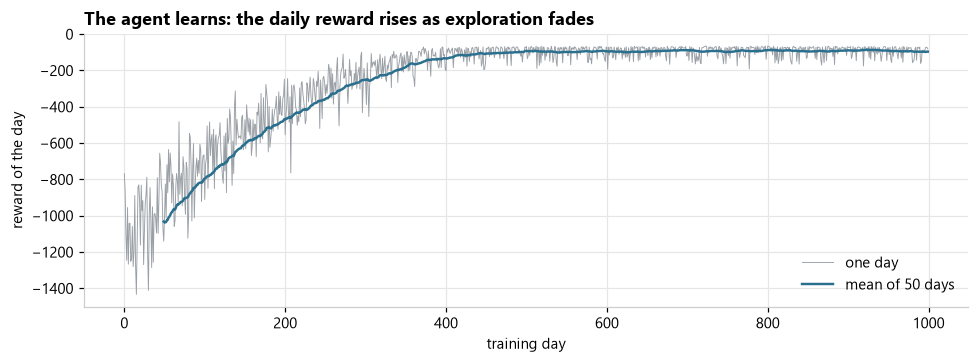

mean reward, days 0-49: -1032
mean reward, days 950-999: -96


In [13]:
ALPHA = 0.1                                    # step size
GAMMA = 0.95                                   # weight of the future
N_DAYS = 1000

rng = np.random.default_rng(0)
Q = np.zeros((N_STATES, len(ACTIONS)))         # Q[temperature bin, action]
returns = []

for day in range(N_DAYS):
    eps = max(0.05, 1 - day / 500)
    T = rng.uniform(14, 26)
    total = 0.0

    for k in range(STEPS_PER_DAY):
        s = state(T)

        # epsilon-greedy: explore with probability eps, otherwise follow the table
        if rng.random() < eps:
            a = rng.integers(len(ACTIONS))
        else:
            a = int(Q[s].argmax())

        T_next = room_step(T, a, k, rng)
        r = reward(T_next, a)

        # the Q-learning update
        target = r + GAMMA * Q[state(T_next)].max()
        Q[s, a] += ALPHA * (target - Q[s, a])

        T = T_next
        total += r

    returns.append(total)

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(returns, color=GREY, lw=0.6, label="one day")
ax.plot(pd.Series(returns).rolling(50).mean(), color=BLUE, label="mean of 50 days")
ax.set(ylim=(-1500, 0), xlabel="training day", ylabel="reward of the day",
       title="The agent learns: the daily reward rises as exploration fades")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

print(f"mean reward, days 0-49: {np.mean(returns[:50]):.0f}")
print(f"mean reward, days 950-999: {np.mean(returns[-50:]):.0f}")

### What the table learned

The whole agent is the table: 30 rows of temperature, three columns of heater power. The left
plot shows it as colours. The right one shows the action with the largest Q in each row, which is
what the agent will do in that state.

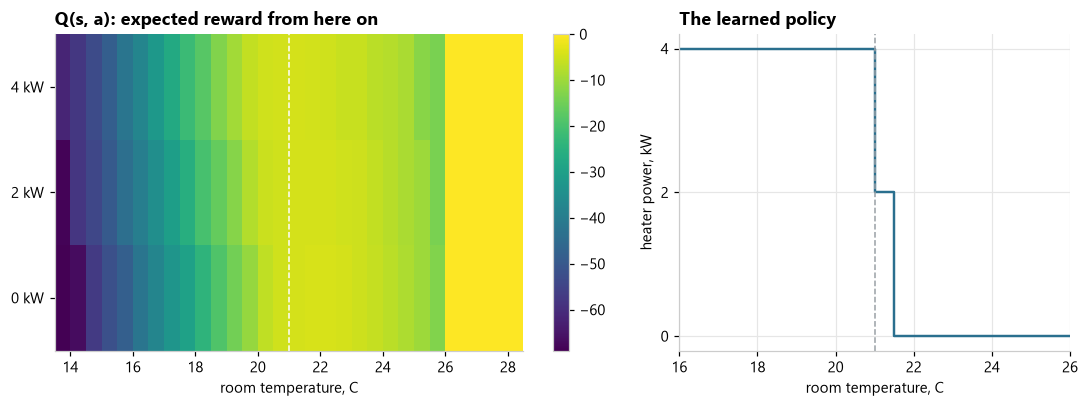

at 19.0 C the agent chooses 4 kW
at 20.6 C the agent chooses 4 kW
at 21.4 C the agent chooses 2 kW
at 23.0 C the agent chooses 0 kW


In [14]:
bin_centres = np.concatenate([[13.75], T_BINS + 0.25])    # a temperature for every bin
policy = Q.argmax(axis=1)                                  # the best action in every bin

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [3, 2]})

image = ax[0].imshow(Q.T, aspect="auto", origin="lower", cmap="viridis",
                     extent=[13.5, 28.5, -0.5, len(ACTIONS) - 0.5])
ax[0].axvline(T_SET, color="white", ls="--", lw=1)
ax[0].grid(False)
ax[0].set(yticks=range(len(ACTIONS)), yticklabels=[f"{p:.0f} kW" for p in ACTIONS],
          xlabel="room temperature, C", title="Q(s, a): expected reward from here on")
fig.colorbar(image, ax=ax[0])

ax[1].step(bin_centres, ACTIONS[policy], where="mid", color=BLUE)
ax[1].axvline(T_SET, color=GREY, ls="--", lw=1)
ax[1].set(xlim=(16, 26), yticks=ACTIONS, xlabel="room temperature, C",
          ylabel="heater power, kW", title="The learned policy")

fig.tight_layout()
plt.show()

for T_show in [19.0, 20.6, 21.4, 23.0]:
    best = ACTIONS[Q[state(T_show)].argmax()]
    print(f"at {T_show} C the agent chooses {best:.0f} kW")

The agent has found a thermostat on its own: full power below 21 °C, half power for the first
half degree above it, off from 21.5 °C. It was never told where 21 °C is. It saw only that rewards
fall away from 21 °C and that the heater costs energy.

Values are lowest at both ends of the plot: from 15 °C or 27 °C the room needs hours to get back
into the band, and every step outside costs reward. Bins at the edges were visited rarely, so their
entries are rough, and that is harmless because the policy never leads there.

                   reward per day  energy, kWh per day  time within 21 ± 0.5 C  highest T, C
policy                                                                                      
Q-learning agent          -85.979               66.150                   0.992        21.566
on/off thermostat         -98.540               65.683                   0.704        21.982
constant 2 kW          -1,143.082               48.000                   0.120        21.463


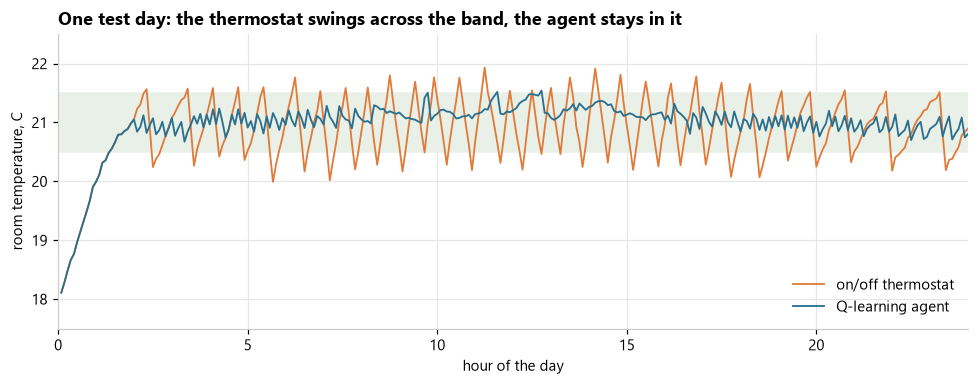

In [15]:
def run_day(policy, seed, T0=18.0):
    rng_day = np.random.default_rng(seed)
    T = T0
    total = 0.0          # reward
    energy = 0.0         # kWh
    temps = []

    for k in range(STEPS_PER_DAY):
        a = policy(T, k)
        T = room_step(T, a, k, rng_day)
        total += reward(T, a)
        energy += ACTIONS[a] * DT
        temps.append(T)

    return total, energy, np.array(temps)


def q_policy(T, k):
    return int(Q[state(T)].argmax())                   # no exploration any more


class Thermostat:
    # the usual on/off controller with a hysteresis band:
    # 4 kW below 20.5 C, off above 21.5 C
    def __init__(self):
        self.on = False

    def __call__(self, T, k):
        if T < 20.5:
            self.on = True
        elif T > 21.5:
            self.on = False
        return 2 if self.on else 0                 # an index into ACTIONS: 4 kW or off


def constant_2kw(T, k):
    return 1                                       # an index into ACTIONS: 2 kW


controllers = {"Q-learning agent": lambda: q_policy,
               "on/off thermostat": Thermostat,
               "constant 2 kW": lambda: constant_2kw}
rows = []
first_day = {}

for name, make in controllers.items():
    results = [run_day(make(), seed=100 + i) for i in range(20)]
    # skip the first 2 hours of warming up
    temps = np.concatenate([res[2][24:] for res in results])
    in_band = np.abs(temps - T_SET) <= 0.5

    rows.append({"policy": name,
                 "reward per day": np.mean([res[0] for res in results]),
                 "energy, kWh per day": np.mean([res[1] for res in results]),
                 "time within 21 ± 0.5 C": in_band.mean(),
                 "highest T, C": temps.max()})
    first_day[name] = results[0][2]

print(pd.DataFrame(rows).set_index("policy").round(3).to_string())

hours = np.arange(1, STEPS_PER_DAY + 1) * DT
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.axhspan(20.5, 21.5, color="#e8f0e8")
for name, colour in [("on/off thermostat", ORANGE), ("Q-learning agent", BLUE)]:
    ax.plot(hours, first_day[name], color=colour, lw=1.2, label=name)
ax.set(xlim=(0, 24), ylim=(17.5, 22.5), xlabel="hour of the day",
       ylabel="room temperature, C",
       title="One test day: the thermostat swings across the band, the agent stays in it")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

Over the first 50 training days the daily reward was about −1030, over the last 50 about −96.
On 20 test days the agent had not trained on:

- the agent keeps the room within 21 ± 0.5 °C 99 % of the time, the thermostat 70 %, with almost
  the same energy: 66.2 and 65.7 kWh a day;
- "constant 2 kW" uses a quarter less energy and leaves the room cold, in the band 12 % of the
  time;
- no controller came near the overheating limit of 25 °C.

The thermostat loses because of its hysteresis band: it switches on at 20.5 °C and off at
21.5 °C, so the room swings from one edge of the band to the other and past them. The agent may
switch every 5 minutes, and it does. A real heater contactor would not last long like that; a
penalty for switching in the reward would stop it.

**The reward is the specification.** The agent did what the reward asked and nothing else. Drop
the comfort term and it learns to switch the heater off for good, because that is the cheapest.
Leave out the overheating penalty and it will happily run the room at 24 °C if that is cheaper
somewhere. Writing the reward is the engineering part of RL.

**Why plants do not train RL on the real thing.** Look at the first days of the training curve:
the agent tried random heater settings for hundreds of simulated days. On a real chemical
reactor that exploration is not allowed. Industrial RL (the cooling of data centres and the
other cases in Lecture 6) is trained first on a model or a digital twin of the plant, then
checked against the existing controller, then let loose on the plant with limits around it.
This room is such a model, five lines of physics.

---

# Part 8. Why the table works, and where it stops

The best table $Q^*$ satisfies the **Bellman optimality equation**

$$Q^*(s, a) = \mathbb{E}\Big[\,r + \gamma \max_{a'} Q^*(s', a') \;\Big|\; s, a\,\Big].$$

Call the right-hand side an operator $\mathcal{T}$ that turns one table into another. For any two
tables it shrinks their largest difference at least by the factor $\gamma$:

$$\max_{s,a}\big|\mathcal{T}Q_1 - \mathcal{T}Q_2\big| \le \gamma\,\max_{s,a}\big|Q_1 - Q_2\big|,$$

because the reward cancels and a maximum moves no more than its arguments. So repeating
$\mathcal{T}$ walks to $Q^*$ from any start. Q-learning applies it to one sampled entry at a time
with a small step, and converges to $Q^*$ when every pair $(s, a)$ keeps being visited
(Watkins and Dayan, 1992).

The table stops working when the state grows. Give the agent the time of day, the outside
temperature and the humidity, ten values each, and the 90 entries become 90 000, most never
visited. The usual answer is to replace the table by a network $Q(\mathbf{s}, a; \boldsymbol{\theta})$
that takes the state as a vector, so that nearby states share what they learn. The guarantee
above is then lost, and training becomes a matter of engineering. The further reading at the end
of this notebook names the methods that do it.

---

# Part 9. Where new methods come from

Lecture 7 is about where methods like these are published and how to find them. Here is a short
guide for the practices and for SIS.

**Where to look.** The syllabus lists the journals: *IEEE Transactions on Industrial
Informatics*, *IEEE Transactions on Industrial Electronics*, *Journal of Manufacturing Systems*,
*Computers in Industry*, *Engineering Applications of Artificial Intelligence*. For vibration and
bearings add *Mechanical Systems and Signal Processing*. Search across all of them with **Google
Scholar**, **IEEE Xplore**, **ScienceDirect** (Elsevier) and **arXiv** for preprints. Most papers
that publish code link it from the paper or from GitHub.

**How to search.** Put the data set and the task into the query:
`"CWRU" bearing fault diagnosis benchmark`, `AI4I 2020 predictive maintenance`,
`SECOM yield prediction imbalanced`. Sort by citations to find the reference papers, then by date
to find what is new. Read the papers that *cite* a classic: that is where the criticism is.

**How to read a result.** Before the accuracy, find three things:

1. **the split.** Random windows from the same recording, or new recordings? In-class work 5 and
   Practice 3 showed how much this changes a number;
2. **the baseline.** Was the new method compared with a logistic regression and a forest on the
   same split, or only with other deep networks?
3. **the spread.** One run, or several seeds with an interval? Part 6 shows why it matters.

**An example for Practice 4.** The CWRU bearing data is the most used data set in bearing
diagnostics, and many papers report 99–100 % accuracy on it. Smith and Randall went through the
recordings one by one with classical signal processing and showed that a part of them cannot be
diagnosed clearly at all, ball faults most of all:

> Smith W.A., Randall R.B. Rolling element bearing diagnostics using the Case Western Reserve
> University data: A benchmark study. *Mechanical Systems and Signal Processing*, 2015,
> vol. 64–65, pp. 100–131. doi:10.1016/j.ymssp.2015.04.021

Keep that paper in mind when your network in Practice 4 confuses the ball faults.

---

# Second hour. Signals, windows and sequences

Parts 1–8 worked on tables of features and a room model of five lines. A plant gives raw streams: 48 000 vibration samples a
second, months of minute readings. The networks below take them almost raw, once the data is fit
to enter a network at all. The simulations are written out in the notebook.

---

# Part 10. Cleaning a log before any model sees it

## 10.1 A reactor log from two historians

Four hours of a reactor. Historian **A** logs the reactor temperature and the feed pump status
every 10 s. Historian **B**, a separate system, logs the heating valve position and the same pump
status every 15 s, and its clock runs **37 s fast**. The temperature has the troubles Lecture 6
lists: noise, a dropout, a sensor frozen on one value, and three spikes from voltage surges. We
built the log ourselves, so the true temperature is known and every cleaning step can be scored
against it.

In [16]:
rng = np.random.default_rng(7)
t = pd.date_range("2026-10-12 08:00", periods=4 * 360, freq="10s")     # 4 h, every 10 s
k = np.arange(len(t))                                       # step number on A's clock

# true process: 80 C, the setpoint goes to 85 C at 09:30,
# first-order response with tau = 10 min
STEP = 540
true = 80 + 5 * (1 - np.exp(-np.clip(k - STEP, 0, None) * 10 / 600))
pump = ((k // 90) % 2 == 0).astype(int)                     # on/off every 15 min

temp = true + rng.normal(0, 0.4, len(t))
temp[rng.random(len(t)) < 0.02] = np.nan                    # scattered lost readings
temp[1200:1230] = np.nan                                    # a 5-minute dropout
temp[800:860] = temp[799]                                   # frozen for 10 minutes
temp[[300, 1010, 1300]] = [1023.0, 96.5, 1180.0]            # voltage surges
A = pd.DataFrame({"temp": temp, "pump": pump}, index=t)

tb = pd.date_range("2026-10-12 08:00", periods=4 * 240, freq="15s")    # B's own sampling
kb = ((tb - t[0]).total_seconds() / 10).astype(int)
valve = np.where(kb >= STEP - 6, 62.0, 45.0)                # opened 1 min before the step
pump_b = pump[np.clip(kb, 0, len(t) - 1)]
clock_b = tb + pd.Timedelta(seconds=37)                     # B's clock is 37 s fast
B = pd.DataFrame({"valve": valve, "pump": pump_b}, index=clock_b)

print("A:", A.shape, "| B:", B.shape)
print(A.describe().loc[["count", "min", "max"]].round(1).to_string())

A: (1440, 2) | B: (960, 2)
           temp      pump
count 1,383.000 1,440.000
min      78.700     0.000
max   1,180.000     1.000


## 10.2 Physical validation, frozen values, gaps

Three rules, each from physics or from how sensors fail:

- **range**: a water-cooled reactor cannot be below 0 °C or above 200 °C;
- **jump**: with a time constant of 10 minutes the temperature cannot move 3 °C in 10 s. A
  first-order process moves at most $(T_{set} - T)\,\Delta t / \tau = 5 \cdot 10/600 \approx 0.08$
  °C per step here, so a reading more than 3 °C from the median of its neighbours is an
  artefact. The median, unlike the mean, is not dragged by the spike it is checking;
- **frozen**: real readings carry noise. Six or more identical readings in a row (a minute)
  mean the sensor or its link has stuck.

Every flagged reading becomes `NaN`. Then short gaps, up to a minute, are filled by linear
interpolation. Longer gaps stay empty: inventing five minutes of a reactor is worse than
admitting we do not know them.

out of range 2, jumps 1, frozen 61, missing from the start 57
still empty after interpolation: 80 readings


error against the truth: raw 1.81 C, cleaned 0.31 C


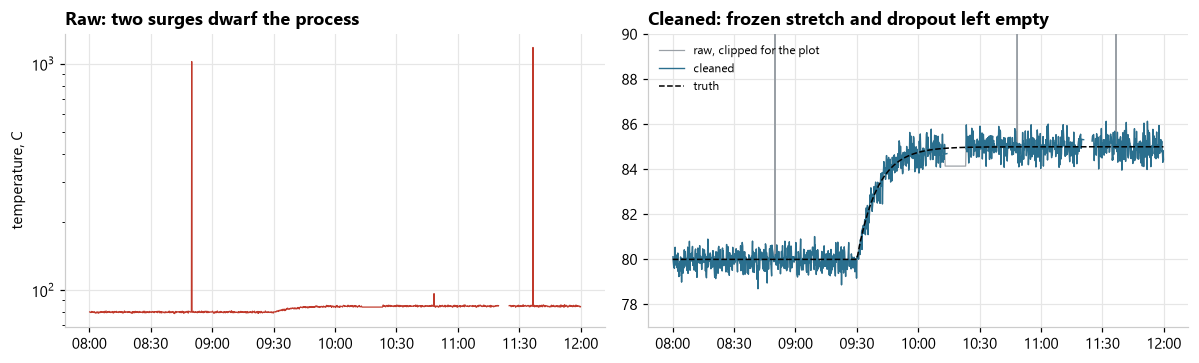

In [17]:
x = A["temp"].copy()
bad_range = (x < 0) | (x > 200)
x[bad_range] = np.nan
local = x.rolling(5, center=True, min_periods=3).median()
bad_jump = (x - local).abs() > 3
x[bad_jump] = np.nan
run_id = (x != x.shift()).cumsum()
bad_frozen = x.groupby(run_id).transform("size").ge(6) & x.notna()
x[bad_frozen] = np.nan
clean = x.interpolate(limit=6, limit_area="inside")

print(f"out of range {bad_range.sum()}, jumps {bad_jump.sum()}, "
      f"frozen {bad_frozen.sum()}, missing from the start {A['temp'].isna().sum()}")
print(f"still empty after interpolation: {clean.isna().sum()} readings")

ok = clean.notna().to_numpy()
raw_error = np.nanmean(np.abs(A["temp"].to_numpy() - true))
clean_error = np.mean(np.abs(clean.to_numpy()[ok] - true[ok]))
print(f"error against the truth: raw {raw_error:.2f} C, cleaned {clean_error:.2f} C")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(A.index, A["temp"], color=RED, lw=0.8)
ax[0].set(yscale="log", ylabel="temperature, C",
          title="Raw: two surges dwarf the process")

ax[1].plot(A.index, A["temp"].clip(70, 100), color=GREY, lw=0.8,
           label="raw, clipped for the plot")
ax[1].plot(clean.index, clean, color=BLUE, lw=0.9, label="cleaned")
ax[1].plot(A.index, true, color="black", lw=1, ls="--", label="truth")
ax[1].set(ylim=(77, 90), title="Cleaned: frozen stretch and dropout left empty")
ax[1].legend(loc="upper left", fontsize=8)
for a in ax:
    a.xaxis.set_major_formatter(mpl.dates.DateFormatter("%H:%M"))
fig.tight_layout()
plt.show()

Each rule found its own trouble. The range caught the two surges (1023 and 1180 °C), the jump
rule the smaller one at 96.5 °C, the frozen rule 61 readings: the ten minutes of copies and the
reading they copied. 57 readings were missing to begin with. After interpolating the short gaps,
80 readings stay empty: the dropout and the frozen stretch.

The mean error against the truth falls from 1.81 °C to 0.31 °C. What remains is the sensor noise
itself: white noise with σ = 0.4 °C has a mean absolute value of $\sigma\sqrt{2/\pi} = 0.32$ °C.

## 10.3 Two clocks

Historian B's valve position is useful only if we know *when* it happened on A's clock. Both
historians log the pump status, so every pump start appears in both. The difference between the
two times of the same start is the clock offset, give or take one sampling period.

In [18]:
starts_A = A.index[A["pump"].diff() == 1]
starts_B = B.index[B["pump"].diff() == 1]
lag = np.array([(starts_B[starts_B >= s][0] - s).total_seconds() for s in starts_A])
offset = pd.Timedelta(seconds=float(np.median(lag)))
print("pump starts seen by B later than by A, s:", lag, "-> offset", offset)

B_fixed = B.copy()
B_fixed.index = B.index - offset
left = A.reset_index(names="time")
right = B_fixed[["valve"]].reset_index(names="time")
merged = pd.merge_asof(left, right, on="time", direction="backward",
                       tolerance=pd.Timedelta("20s"))

opened = merged.loc[merged["valve"].diff() > 0, "time"].iloc[0]
opened_raw = B.index[B["valve"].diff() > 0][0]
print(f"valve opened, B's clock as it is: {opened_raw:%H:%M:%S};  "
      f"corrected: {opened:%H:%M:%S}; true: {t[STEP - 6]:%H:%M:%S}")

pump starts seen by B later than by A, s: [37. 37. 37. 37. 37. 37. 37.] -> offset 0 days 00:00:37
valve opened, B's clock as it is: 09:29:37;  corrected: 09:29:00; true: 09:29:00


All seven pump starts reach B exactly 37 s late, so the offset is 37 s. With it removed, the
valve opens at 09:29:00, the true time. Uncorrected, it would seem to open at 09:29:37, only
23 s before the temperature starts to rise at 09:30 instead of 60 s. Any model of the delay from
valve to temperature, a PID tuning or a network, would learn the wrong dead time. `merge_asof`
then joins the two logs on the corrected clock, taking for every A reading the last B reading no
older than 20 s.

## 10.4 A Kalman filter

The cleaned signal still carries ±0.4 °C of noise. A moving average removes noise and adds lag:
after the setpoint step it reports the average of the last three minutes, which is the past.

A **Kalman filter** carries a small model of the process. Ours keeps two numbers, the temperature
and how fast it is changing, $\mathbf{x} = (T, \dot T)^\top$, and their covariance $\mathbf{P}$.
At every reading $z$ it does two things.

- **Predict.** In one step of 10 s the temperature moves by $\dot T$ (in °C per step) and the
  rate stays. The uncertainty grows by $\mathbf{Q}$, because the rate itself may change.
- **Update.** Compare the prediction with the reading and move both numbers towards it by the
  **Kalman gain** $\mathbf{k}$.

$$\mathbf{x}^- = \mathbf{F} \mathbf{x}, \quad \mathbf{P}^- = \mathbf{F} \mathbf{P} \mathbf{F}^\top + \mathbf{Q}, \qquad \mathbf{k} = \frac{\mathbf{P}^- \mathbf{h}}{\mathbf{h}^\top \mathbf{P}^- \mathbf{h} + r}, \quad \mathbf{x} = \mathbf{x}^- + \mathbf{k}\,(z - \mathbf{h}^\top \mathbf{x}^-), \quad \mathbf{P} = (\mathbf{I} - \mathbf{k} \mathbf{h}^\top)\,\mathbf{P}^-$$

with $\mathbf{F} = \begin{pmatrix} 1 & 1 \\ 0 & 1 \end{pmatrix}$ (one step), $\mathbf{h} = (1, 0)^\top$
(we measure only the temperature), $r = 0.4^2$ the variance of the sensor noise, and
$\mathbf{Q} = q \begin{pmatrix} 1/3 & 1/2 \\ 1/2 & 1 \end{pmatrix}$, the covariance that a random
change of the rate with variance $q$ per step leaves on $(T, \dot T)$. When a reading is missing,
only the prediction runs.

The gain is the whole idea. Its first component is
$k_T = P^-_{TT} / (P^-_{TT} + r)$, the share of the total uncertainty that sits in the
prediction. A confident model ($P^-_{TT} \ll r$) gives $k_T \approx 0$ and the filter hardly
listens to the sensor; a noise-free sensor ($r \ll P^-_{TT}$) gives $k_T \approx 1$ and the
filter copies it. $q$ moves the balance: a larger $q$ keeps $\mathbf{P}^-$ large and the filter
nervous.

                       mean error, C  mean error in the 10 min after the step, C
signal                                                                          
cleaned readings               0.309                                       0.255
moving average, 3 min          0.113                                       0.482
Kalman filter                  0.135                                       0.237


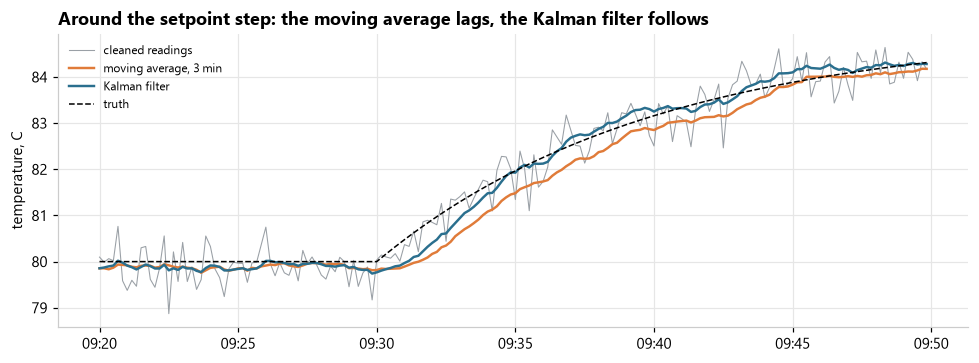

In [19]:
def kalman(z, q, r):
    # z: readings, one per 10 s step, NaN where missing; returns the filtered temperature
    F = np.array([[1.0, 1.0], [0.0, 1.0]])                   # temperature, rate; one step
    h = np.array([1.0, 0.0])
    Q_proc = q * np.array([[1 / 3, 1 / 2], [1 / 2, 1.0]])    # process noise covariance

    # start at the first reading, at rest, with a unit covariance
    first_reading = z[np.flatnonzero(~np.isnan(z))[0]]
    x = np.array([first_reading, 0.0])
    P = np.eye(2)
    out = []
    for zk in z:
        x, P = F @ x, F @ P @ F.T + Q_proc                   # predict
        if not np.isnan(zk):                     # update, when there is a reading
            gain = P @ h / (h @ P @ h + r)
            x = x + gain * (zk - h @ x)
            P = P - np.outer(gain, h @ P)
        out.append(x[0])
    return np.array(out)


Q_RATE = 1e-5                    # variance of the change of the rate, (C/step)^2
z = clean.to_numpy()
kf = kalman(z, q=Q_RATE, r=0.4 ** 2)
ma = clean.rolling(18, min_periods=1).mean().to_numpy()        # 3-minute moving average

signals = [("cleaned readings", z), ("moving average, 3 min", ma), ("Kalman filter", kf)]
rows = []
for name, est in signals:
    m = ~np.isnan(est)
    after = m & (k >= STEP) & (k < STEP + 60)        # the 10 minutes after the step
    rows.append({"signal": name,
                 "mean error, C": np.mean(np.abs(est[m] - true[m])),
                 "mean error in the 10 min after the step, C":
                     np.mean(np.abs(est[after] - true[after]))})
print(pd.DataFrame(rows).set_index("signal").round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 3.4))
w = slice(STEP - 60, STEP + 120)
ax.plot(t[w], z[w], color=GREY, lw=0.7, label="cleaned readings")
ax.plot(t[w], ma[w], color=ORANGE, label="moving average, 3 min")
ax.plot(t[w], kf[w], color=BLUE, label="Kalman filter")
ax.plot(t[w], true[w], color="black", ls="--", lw=1, label="truth")
ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%H:%M"))
title = "Around the setpoint step: the moving average lags, the Kalman filter follows"
ax.set(ylabel="temperature, C", title=title)
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

On the flat stretches the moving average is a little smoother (mean error 0.113 against 0.135).
In the ten minutes after the step it is twice as far from the truth, 0.482 against 0.237: it
averages the past, while the filter knows that the temperature has a rate. $q$ sets the
trade-off between noise and lag (question 10 at the end).

Lecture 6 also names wavelet transforms for cleaning signals. They split a signal into scales
and drop the fine scales where the noise sits, keeping sharp events that a moving average would
smear. We do not use them here.

---

# Part 11. Sliding windows: from a stream to a tensor

A network wants inputs of a fixed size, and a sensor stream has no size: it just goes on. The
**sliding window** cuts it. At every moment take the last $W$ readings of all sensors; one window
is one training example. Lecture 6's example takes the last 60 seconds. The pump data of
Practice 1 is logged every minute, so we average it to 10 minutes and take the last hour,
$W = 6$.

The cleaning is the one from Practice 1, done quickly: `sensor_15` is empty and `sensor_50`
misses a third of its values, so both go; the remaining gaps are interpolated.

In [20]:
def load_pump():
    path = next(dataset_folder("pump_sensor").glob("*.csv*"))
    df = pd.read_csv(path, parse_dates=["timestamp"])
    df = df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")])
    return df.set_index("timestamp")


pump = load_pump()
DROPPED = ("sensor_15", "sensor_50")
SENS = [c for c in pump.columns if c.startswith("sensor_") and c not in DROPPED]
BROKEN = pump.index[pump["machine_status"] == "BROKEN"]
X10 = pump[SENS].interpolate(limit_direction="both").resample("10min").mean()
normal10 = (pump["machine_status"] == "NORMAL").resample("10min").min().astype(bool)
print(f"{len(SENS)} sensors, {len(X10)} ten-minute steps, {len(BROKEN)} breakdowns:")
print([f"{b:%d %b %H:%M}" for b in BROKEN])

pump_sensor: Kaggle nphantawee/pump-sensor-data


50 sensors, 22032 ten-minute steps, 7 breakdowns:
['12 Apr 21:55', '18 Apr 00:30', '19 May 03:18', '25 May 00:30', '28 Jun 22:00', '08 Jul 00:11', '25 Jul 14:00']


In [21]:
W = 6                                     # one hour of 10-minute steps
TRAIN_END = pd.Timestamp("2018-06-20")

# scale with the statistics of normal operation in the training period only
ref = X10[(X10.index < TRAIN_END) & normal10]
scaled = (X10 - ref.mean()) / (ref.std() + 1e-6)
Zp = scaled.clip(-10, 10).to_numpy(np.float32)

ends = np.arange(W - 1, len(Zp))                          # a window ends at every step
windows = np.stack([Zp[e - W + 1:e + 1] for e in ends])   # (windows, time, sensors)
t_end = X10.index[ends]
win_normal = np.array([normal10.iloc[e - W + 1:e + 1].all() for e in ends])
before_fail = np.zeros(len(ends), bool)
for b in BROKEN:
    before_fail |= (t_end > b - pd.Timedelta("24h")) & (t_end <= b)

print("tensor shape:", windows.shape, "= (windows, time steps, sensors)")
print("one window flattened for a dense network:", windows[0].ravel().shape)

tensor shape: (22027, 6, 50) = (windows, time steps, sensors)
one window flattened for a dense network: (300,)


---

# Part 12. An autoencoder: learn normal, flag the rest

Seven breakdowns in five months are too few to learn what a breakdown looks like. Normal
operation fills months. An **autoencoder** uses only that. It is a network that squeezes its
input through a narrow middle and has to rebuild it on the other side:

$$\mathbf{x} \in \mathbb{R}^{300} \;\xrightarrow{\;f\;}\; 64 \;\to\; \mathbf{c} \in \mathbb{R}^{8} \;\to\; 64 \;\xrightarrow{\;g\;}\; \hat{\mathbf{x}} \in \mathbb{R}^{300}$$

Training minimises $\lVert \mathbf{x} - g(f(\mathbf{x})) \rVert^2$ over normal windows only. Eight
numbers cannot hold 300 independent ones, so the network has to learn how the 50 sensors move
together in normal operation, and keep just that. A window that breaks those patterns comes out
badly rebuilt, and the **reconstruction error** (the MSE between input and output) jumps. A
threshold on that error is the alarm.

In-class work 2 did the same with PCA and two components. If all the layers were linear, the
best 8-number code would be exactly the projection on the first 8 principal components; the
ReLUs let the autoencoder bend that flat subspace into a curved one.

Training data: normal windows before 20 June, without the 24 hours before each breakdown. That
leaves four breakdowns in the training period and three after it, on 28 June, 8 July and
25 July. The threshold is the 99.5th percentile of the training error.

trained on 10322 normal windows; threshold 1.42


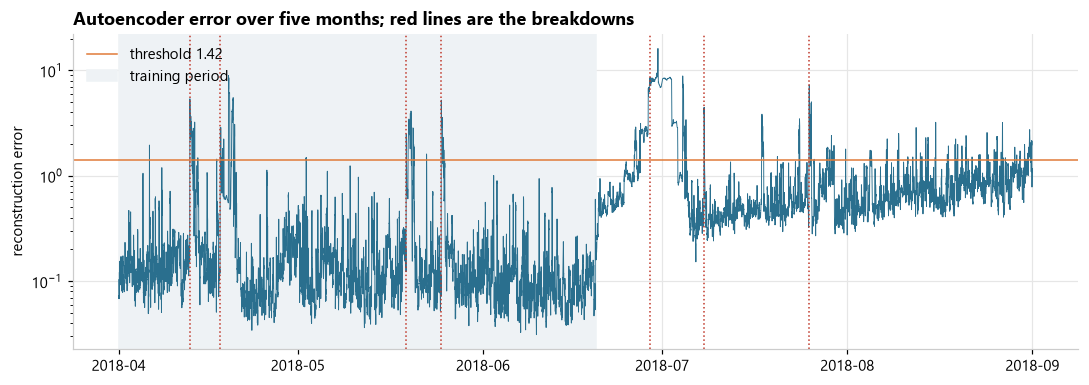

In [22]:
torch.manual_seed(0)
n_in = windows.shape[1] * windows.shape[2]
ae = nn.Sequential(
    nn.Linear(n_in, 64),
    nn.ReLU(),
    nn.Linear(64, 8),          # the 8-number code
    nn.ReLU(),
    nn.Linear(8, 64),
    nn.ReLU(),
    nn.Linear(64, n_in),
).to(DEVICE)
Xw_np = windows.reshape(len(windows), -1)                     # (windows, 300), for PCA
Xw = torch.tensor(Xw_np).to(DEVICE)
train_idx = np.flatnonzero((t_end < TRAIN_END) & win_normal & ~before_fail)

opt = torch.optim.Adam(ae.parameters(), lr=1e-3)
rng_ae = np.random.default_rng(0)
n_batches = len(train_idx) // 256
for epoch in range(30):
    for i in np.array_split(rng_ae.permutation(train_idx), n_batches):
        opt.zero_grad()
        loss = ((ae(Xw[i]) - Xw[i]) ** 2).mean()
        loss.backward()
        opt.step()

with torch.no_grad():
    err = ((ae(Xw) - Xw) ** 2).mean(axis=1).cpu().numpy()
thr = np.quantile(err[train_idx], 0.995)
print(f"trained on {len(train_idx)} normal windows; threshold {thr:.2f}")

# the same alarm with PCA, eight components, as in In-class work 2
from sklearn.decomposition import PCA
pca = PCA(8).fit(Xw_np[train_idx])
rebuilt = pca.inverse_transform(pca.transform(Xw_np))
err_pca = ((rebuilt - Xw_np) ** 2).mean(axis=1)
thr_pca = np.quantile(err_pca[train_idx], 0.995)

e = pd.Series(err, index=t_end)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(e.index, e.clip(upper=20), color=BLUE, lw=0.6)
ax.axhline(thr, color=ORANGE, lw=1, label=f"threshold {thr:.2f}")
ax.axvspan(e.index[0], TRAIN_END, color="#eef2f5", label="training period")
for b in BROKEN:
    ax.axvline(b, color=RED, lw=1, ls=":")
ax.set(yscale="log", ylabel="reconstruction error",
       title="Autoencoder error over five months; red lines are the breakdowns")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

In [23]:
def first_warning(errors, threshold, b, hours=48):
    m = (t_end > b - pd.Timedelta(f"{hours}h")) & (t_end <= b)
    hit = t_end[m][errors[m] > threshold]
    if not len(hit):
        return "no warning"
    hours_before = (b - hit[0]).total_seconds() / 3600
    return f"{hours_before:5.1f} h before"


def episodes(flags):
    # an alarm episode is a run of at least 6 flagged windows in a row:
    # one hour above the threshold
    flags = pd.Series(flags)
    runs = flags.ne(flags.shift()).cumsum()
    lengths = flags.groupby(runs).agg(["first", "size"])
    return int(((lengths["first"]) & (lengths["size"] >= 6)).sum())


after = (t_end >= TRAIN_END) & win_normal & ~before_fail
days_after = (t_end[-1] - TRAIN_END).days
detectors = [("autoencoder", err, thr), ("PCA, 8 components", err_pca, thr_pca)]
for name, errs, th in detectors:
    print(f"{name}:")
    for b in BROKEN[BROKEN > TRAIN_END]:
        print(f"   breakdown {b:%d %b %H:%M}: first warning {first_warning(errs, th, b)}")
    flags = (errs > th) & after
    print(f"   normal windows after training above the threshold: "
          f"{flags[after].mean():.1%}; "
          f"alarm episodes of an hour or more: {episodes(flags)} in {days_after} days")

print(f"median error of normal windows: training period {np.median(err[train_idx]):.2f}, "
      f"after it {np.median(err[after]):.2f}")
up = e[(e.index >= TRAIN_END)].rolling(36).median()
first_cross = up[up > thr].index[0]
print(f"the 6-hour median error first crosses the threshold on {first_cross:%d %b %H:%M}")

autoencoder:
   breakdown 28 Jun 22:00: first warning  40.2 h before
   breakdown 08 Jul 00:11: first warning   0.2 h before
   breakdown 25 Jul 14:00: first warning  40.2 h before
   normal windows after training above the threshold: 7.6%; alarm episodes of an hour or more: 45 in 72 days
PCA, 8 components:
   breakdown 28 Jun 22:00: first warning  47.3 h before
   breakdown 08 Jul 00:11: first warning   0.0 h before
   breakdown 25 Jul 14:00: first warning  40.0 h before
   normal windows after training above the threshold: 5.2%; alarm episodes of an hour or more: 19 in 72 days
median error of normal windows: training period 0.11, after it 0.63
the 6-hour median error first crosses the threshold on 26 Jun 11:50


Three test breakdowns, three warnings: about 40 h, a few minutes and 40 h before. Now the false
alarms: after training, about 8 % of the normal windows are above the threshold, and there are
some 45 alarm episodes of an hour or more in 72 days, more than one every two days. With that many alarms, a warning in
the two days before a breakdown would come even by chance.

The plot shows why. The median error of normal windows is about 0.1 in the training period and
about 0.6 after it. From late June the pump runs unlike anything in April to June: the 6-hour median error
crosses the threshold on 26 June, two and a half days before the breakdown of 28 June, and stays
high. Is that the coming failure or a new normal regime? The data cannot tell. An anomaly
detector flags everything new, faults and harmless changes alike. This is the drift of In-class
work 4 again.

PCA with eight components gives the same warnings with fewer alarms, 19 episodes (PCA has no
random start, so this number is the same on every machine). On this data
the autoencoder's freedom to bend buys nothing. In a plant it would be retrained on recent normal
data, weeks old rather than months, and its alarms checked by a person before anyone stops the
pump.

---

# Part 13. The Fourier transform and the spectrogram

## 13.1 A signal that looks like noise

Lecture 6: a raw vibration signal often looks like noise, and the defect hides in it. Here is one
second of a simulated bearing with a defect on its outer race, sampled at 12 kHz. The shaft turns
at 25 Hz. Every time a ball rolls over the defect, about 90 times a second, it strikes, and the
strike rings the housing at its resonance near 3 kHz for a few milliseconds. On top of that,
noise.

The **Fourier transform** writes the signal as a sum of sine waves and shows how strong each
frequency is. For $N$ samples $x_n$ taken at the rate $f_s$,

$$X_k = \sum_{n=0}^{N-1} x_n\, e^{-2\pi i k n / N}, \qquad f_k = k\,\frac{f_s}{N}$$

$X_k$ is the correlation of the signal with a sine of frequency $f_k$; one second of data gives
bins 1 Hz apart. The **spectrogram** does the same for short slices one after another: time
across, frequency up, colour for strength. Short slices see quick events and blur the frequency,
since a slice of $N$ samples resolves only $f_s / N$.

The **envelope spectrum** first takes the outline of the signal, $|x + i\,\mathcal{H}[x]|$ with
$\mathcal{H}$ the Hilbert transform, which rises at every strike. Then it takes the spectrum of
that outline: it shows how *often* the strikes come, whatever the frequency at which they ring.

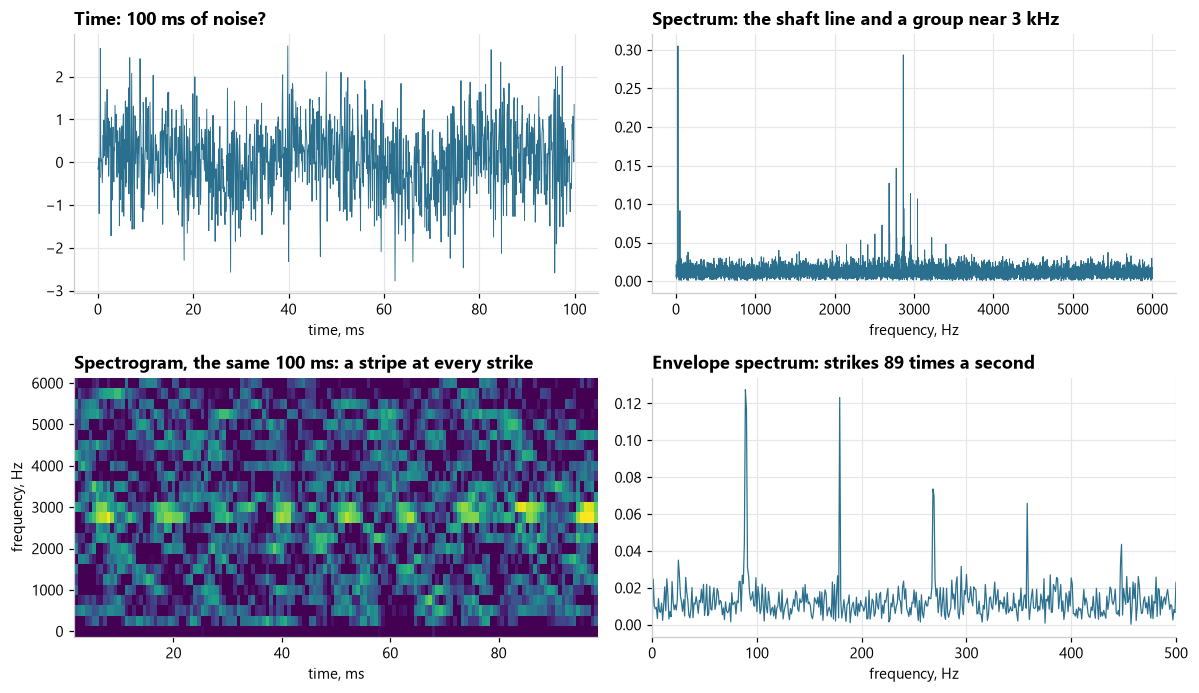

strongest envelope line: 89.0 Hz; the defect frequency is 3.58 x 25 Hz = 89.5 Hz


In [24]:
from scipy.signal import spectrogram, hilbert

FSV = 12_000          # sampling rate, Hz
NV = 3_000            # samples per signal in Part 14


def bearing_signal(kind, rng, n=NV, fr=None):
    # kind 0: healthy; 1: outer race defect; 2: inner race defect
    tt = np.arange(n) / FSV
    fr = rng.uniform(24, 26) if fr is None else fr                 # shaft speed, Hz

    # the shaft and its second harmonic, at random phases, plus noise
    phase_1 = rng.uniform(0, 6)
    phase_2 = rng.uniform(0, 6)
    x = (0.3 * np.sin(2 * np.pi * fr * tt + phase_1)
         + 0.1 * np.sin(2 * np.pi * 2 * fr * tt + phase_2))
    x += rng.normal(0, rng.uniform(0.4, 0.8), n)

    if kind:
        # how often a ball hits the defect
        f_def = (3.58 if kind == 1 else 5.42) * fr
        # one strike: the housing rings at its resonance and dies away
        resonance = rng.uniform(2500, 3500)
        ring_t = np.arange(120)
        ring = np.exp(-ring_t / 25) * np.sin(2 * np.pi * resonance * ring_t / FSV)
        amp = rng.uniform(1.0, 2.0)
        for t0 in np.arange(rng.uniform(0, 1 / f_def), n / FSV, 1 / f_def):
            i = int(t0 * FSV)
            # an inner race defect turns with the shaft and is struck hard only
            # in the load zone
            a = amp if kind == 1 else amp * 0.5 * (1 + np.cos(2 * np.pi * fr * t0))
            x[i:i + 120] += a * ring[:n - i]
    return x


# one second of an outer race defect, shaft at 25 Hz
x = bearing_signal(1, np.random.default_rng(3), n=FSV, fr=25.0)
tt = np.arange(len(x)) / FSV
fig, ax = plt.subplots(2, 2, figsize=(11, 6.4))

ax[0, 0].plot(tt[:1200] * 1000, x[:1200], color=BLUE, lw=0.6)
ax[0, 0].set(xlabel="time, ms", title="Time: 100 ms of noise?")

spec = np.abs(np.fft.rfft(x)) / len(x) * 2
f = np.fft.rfftfreq(len(x), 1 / FSV)
ax[0, 1].plot(f, spec, color=BLUE, lw=0.6)
ax[0, 1].set(xlabel="frequency, Hz",
             title="Spectrum: the shaft line and a group near 3 kHz")

fs_, ts_, S = spectrogram(x[:1200], FSV, nperseg=48, noverlap=40)
db = 10 * np.log10(S + 1e-9)
ax[1, 0].pcolormesh(ts_ * 1000, fs_, db, shading="auto", cmap="viridis",
                    vmin=np.percentile(db, 30), vmax=db.max())
ax[1, 0].set(xlabel="time, ms", ylabel="frequency, Hz",
             title="Spectrogram, the same 100 ms: a stripe at every strike")
ax[1, 0].grid(False)

env = np.abs(hilbert(x - x.mean()))
envs = np.abs(np.fft.rfft(env - env.mean())) / len(env) * 2
band = (f > 20) & (f < 500)
peak = f[band][np.argmax(envs[band])]
ax[1, 1].plot(f, envs, color=BLUE, lw=0.8)
ax[1, 1].set(xlim=(0, 500), xlabel="frequency, Hz",
             title=f"Envelope spectrum: strikes {peak:.0f} times a second")

fig.tight_layout()
plt.show()
print(f"strongest envelope line: {peak:.1f} Hz; "
      f"the defect frequency is 3.58 x 25 Hz = {3.58 * 25:.1f} Hz")

Read the four panels in turn.

- Time: peaks up to about ±2.5, no pattern a person can see.
- Spectrum: a line at 25 Hz from the shaft and a group of lines near 2.8 kHz, the housing
  resonance that the strikes excite. It says that something rings. It does not say how often.
- Spectrogram of the same 100 ms: the 3 kHz band lights up every 11 ms, one stripe per strike.
  Each slice has 48 samples, 4 ms, so the frequency is blurred over 250 Hz and the strikes are
  sharp in time.
- Envelope spectrum: lines at 89 Hz and its multiples. 89 Hz is 3.58 × 25 Hz, the outer race
  frequency. This is how a vibration engineer reads a bearing.

The spectrogram is a picture, and a CNN reads pictures.

**How many operations does the spectrum of $N$ samples cost?**

<details><summary>Answer</summary>

By the formula above, each of the $N$ values $X_k$ is a sum of $N$ products, so $N^2$ operations
in total: $1.4 \cdot 10^8$ for one second of the 12 kHz signal. The **fast Fourier transform**
(Cooley and Tukey, 1965) splits the sum into the even and the odd samples. Each half is itself a
transform of length $N/2$, and the two halves combine in $N$ more operations. Repeating the split
gives $N\log_2 N$ operations, about $1.6 \cdot 10^5$ here, nearly a thousand times fewer.
`np.fft.rfft` is an FFT. The cell below times both on the same signal.

</details>

In [25]:
def dft(x):
    # the formula as written: one row of the matrix e^(-2 pi i k n / N) per frequency k
    n = np.arange(len(x))
    k = n[:, None]
    return np.exp(-2j * np.pi * k * n / len(x)) @ x


x_short = x[:4096]
t0 = time.perf_counter()
slow = dft(x_short)
t_dft = time.perf_counter() - t0

t0 = time.perf_counter()
fast = np.fft.fft(x_short)
t_fft = time.perf_counter() - t0

print(f"N = {len(x_short)}: the formula {t_dft * 1000:.0f} ms, "
      f"the FFT {t_fft * 1000:.2f} ms; same result: {np.allclose(slow, fast)}")

N = 4096: the formula 680 ms, the FFT 0.42 ms; same result: True


---

# Part 14. A CNN reads spectrograms

## 14.1 The data and a baseline

900 simulated signals of 0.25 s, three classes of 300: healthy, outer race defect, inner race
defect. Speed, noise level, strike strength and resonance change from signal to signal. The
split is 600 / 150 / 150 for train, validation and test.

The baseline is the method of Practice 4, Section 1: a few numbers per signal (rms, kurtosis,
crest factor) and a random forest.

In [26]:
from scipy import stats
from sklearn.metrics import confusion_matrix

CLASSES = ["healthy", "outer race", "inner race"]
rng_v = np.random.default_rng(1)
yv = np.repeat([0, 1, 2], 300)
sig = np.array([bearing_signal(c, rng_v) for c in yv])
perm = np.random.default_rng(0).permutation(len(yv))
itr, iva, ite = perm[:600], perm[600:750], perm[750:]

rms = sig.std(axis=1)
crest = np.abs(sig).max(axis=1) / sig.std(axis=1)
feats = np.c_[rms, stats.kurtosis(sig, axis=1), crest]

rf = RandomForestClassifier(300, random_state=0, n_jobs=-1).fit(feats[itr], yv[itr])
accuracy = (rf.predict(feats[ite]) == yv[ite]).mean()
print(f"forest on rms, kurtosis, crest factor: test accuracy {accuracy:.3f}")
print(confusion_matrix(yv[ite], rf.predict(feats[ite])))

forest on rms, kurtosis, crest factor: test accuracy 0.573
[[36  5  6]
 [ 5 32 13]
 [14 21 18]]


## 14.2 The convolutional network

The spectrogram of each signal is a small picture, 65 frequencies by 45 time slices. A
**convolution** slides a little 3 × 3 kernel $\mathbf{K}$ over the picture $\mathbf{S}$ and
answers at every position:

$$y_{ij} = \sum_{u=-1}^{1} \sum_{v=-1}^{1} K_{uv}\, S_{i+u,\, j+v} + b$$

This is the dot product of the kernel with the 3 × 3 patch around $(i, j)$, so $y_{ij}$ is large
where the patch looks like the kernel: "is my pattern here?". The same nine weights are used at
every position. The first layer has 8 kernels, $8 \cdot (9 + 1) = 80$ weights, however large the
picture, and a stripe is recognised wherever it falls. After each convolution, **pooling** halves
the picture and keeps the strongest answer of every 2 × 2 block. Two such layers, then one dense
layer to the three classes:

$$1 \times 65 \times 45 \;\xrightarrow{\text{8 kernels, pool}}\; 8 \times 32 \times 22 \;\xrightarrow{\text{16 kernels, pool}}\; 16 \times 16 \times 11 \;\to\; 3$$

Nobody tells the network to look for stripes or their spacing. Training is the loop of Parts 3–4
with early stopping on the validation part.

In [27]:
_, _, S = spectrogram(sig, FSV, nperseg=128, noverlap=64)
S = np.log10(S + 1e-6)
S = ((S - S[itr].mean()) / S[itr].std()).astype(np.float32)
St = torch.tensor(S)[:, None].to(DEVICE)          # add a channel axis
yt_v = torch.tensor(yv).to(DEVICE)
print("input tensor:", tuple(St.shape), "= (signals, channels, frequencies, time slices)")

torch.manual_seed(0)
cnn = nn.Sequential(
    nn.Conv2d(1, 8, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(8, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(16 * 16 * 11, 3),
).to(DEVICE)
print("weights:", sum(p.numel() for p in cnn.parameters()))

ce_loss = nn.CrossEntropyLoss()           # three classes: softmax and log-loss in one
opt = torch.optim.Adam(cnn.parameters(), lr=1e-3)
rng_cnn = np.random.default_rng(0)
best_cnn = (np.inf, None, -1)             # validation loss, weights, epoch
for epoch in range(100):
    cnn.train()
    for i in np.array_split(rng_cnn.permutation(itr), len(itr) // 32):
        opt.zero_grad()
        loss = ce_loss(cnn(St[i]), yt_v[i])
        loss.backward()
        opt.step()
    cnn.eval()
    with torch.no_grad():
        v = ce_loss(cnn(St[iva]), yt_v[iva]).item()
    if v < best_cnn[0]:
        best_cnn = (v, copy.deepcopy(cnn.state_dict()), epoch)
    if epoch - best_cnn[2] >= 8:
        break
cnn.load_state_dict(best_cnn[1])
with torch.no_grad():
    pred = cnn(St[ite]).argmax(1).cpu().numpy()
print(f"stopped at epoch {epoch}, best {best_cnn[2]}; "
      f"CNN on spectrograms: test accuracy {(pred == yv[ite]).mean():.3f}")
print(confusion_matrix(yv[ite], pred))

input tensor: (900, 1, 65, 45) = (signals, channels, frequencies, time slices)
weights: 9699


stopped at epoch 67, best 59; CNN on spectrograms: test accuracy 0.960
[[46  0  1]
 [ 1 48  1]
 [ 1  2 50]]


The forest on three time features gets 0.573. It separates healthy from damaged fairly well (36
of 47 healthy signals right) and cannot tell the outer race from the inner race: both make
spikes, both raise the kurtosis.

The CNN on spectrograms gets about 0.96, 144 of 150 in our run. It has 9699 weights, 8451 of them in the last
dense layer, and was told nothing about defect frequencies. The spacing of the stripes and the
way their strength changes are in the picture, and its kernels found them. That is the point of
Lecture 6: the network extracts the features from raw data. The price is 900 labelled examples.
On a real plant the labelled spectrograms of every fault are the expensive part, and Practice 4,
Section 2 shows what happens when they come from one recording each.

---

# Part 15. An LSTM predicts the remaining useful life

## 15.1 A fleet run to failure

Lecture 6 names the main task for sequences: the **remaining useful life** (RUL), the number of
cycles left before a machine fails. We simulate 100 machines. Each starts healthy and wears out
along its own curve, at its own speed, failing after 150 to 350 cycles. Four sensors per cycle:
two follow the wear, one follows it through heavy noise, one is pure noise. We train on 60
machines, validate on 20 and test on 20 machines the models have never seen.

The target is the RUL capped at 125 cycles. Far from failure nobody can tell 300 cycles from
200, and nobody needs to. This is the usual convention for the NASA C-MAPSS data of Practice 7.

In [28]:
def machine(rng):
    L = int(rng.uniform(150, 350))
    c = np.arange(L)
    b = rng.uniform(3, 6) / L
    wear = np.expm1(b * c) / np.expm1(b * L)             # 0 when new, 1 at failure

    # two sensors follow the wear, one through heavy noise, one is pure noise
    s1 = 2 * wear + rng.normal(0, 0.15, L)
    s2 = -1.5 * wear ** 2 + rng.normal(0, 0.15, L)
    s3 = wear + rng.normal(0, 0.5, L)
    s4 = rng.normal(0, 0.3, L)
    offsets = rng.normal(0, 0.1, 4)                      # each machine's own calibration
    s = np.c_[s1, s2, s3, s4] + offsets
    return s.astype(np.float32), (L - 1 - c).astype(np.float32)


rng_f = np.random.default_rng(0)
fleet = [machine(rng_f) for _ in range(100)]
WL = 30               # cycles per window
CAP = 125             # the RUL is capped here


def rul_windows(units, stride=3):
    # windows of WL cycles, the RUL at the last cycle divided by CAP,
    # and the machine of each window
    X, Y, U = [], [], []
    for u, (s, rul) in enumerate(units):
        for e in range(WL, len(s) + 1, stride):
            X.append(s[e - WL:e])
            Y.append(min(rul[e - 1], CAP) / CAP)
            U.append(u)
    X = torch.tensor(np.array(X)).to(DEVICE)
    Y = torch.tensor(np.array(Y)).to(DEVICE)
    return X, Y, np.array(U)


Xr_tr, yr_tr, _ = rul_windows(fleet[:60])
Xr_va, yr_va, _ = rul_windows(fleet[60:80])
Xr_te, yr_te, u_te = rul_windows(fleet[80:])
print("train", tuple(Xr_tr.shape), "| validation", tuple(Xr_va.shape),
      "| test", tuple(Xr_te.shape), "= (windows, cycles, sensors)")

train (4469, 30, 4) | validation (1429, 30, 4) | test (1503, 30, 4) = (windows, cycles, sensors)


## 15.2 The LSTM

A dense network sees the 30 × 4 window as 120 unrelated numbers. A **recurrent** network reads it
in order, one cycle at a time, and carries a memory from cycle to cycle. The **LSTM** (long
short-term memory) is the standard kind. Its memory $\mathbf{c}_t$ is updated through gates,
vectors of numbers between 0 and 1 computed from the current input and the last output:

$$\mathbf{c}_t = \mathbf{f}_t \odot \mathbf{c}_{t-1} + \mathbf{i}_t \odot \mathbf{g}_t, \qquad \mathbf{h}_t = \mathbf{o}_t \odot \tanh(\mathbf{c}_t)$$

The forget gate $\mathbf{f}_t$ decides how much of the old memory to keep, the input gate
$\mathbf{i}_t$ how much of the new candidate $\mathbf{g}_t$ to add, and $\odot$ multiplies
element by element. With $\mathbf{f}_t$ near 1 the memory passes from cycle to cycle almost
unchanged, so a slow trend over 30 cycles survives the noise of each one. The last output
$\mathbf{h}_{30}$ goes to a linear layer that gives the RUL. Transformers, the third family in
the lecture, read the whole window at once and learn which cycles to attend to; Part 16 tries
one.

Three models stand against it: the mean RUL of the training windows, a dense network on the last
cycle only, and a dense network on the whole flattened window.

mean RUL of the training windows   test RMSE  41.3 cycles
dense, last cycle only             test RMSE  17.5 cycles
dense, whole window                test RMSE  16.8 cycles
LSTM                               test RMSE  15.0 cycles


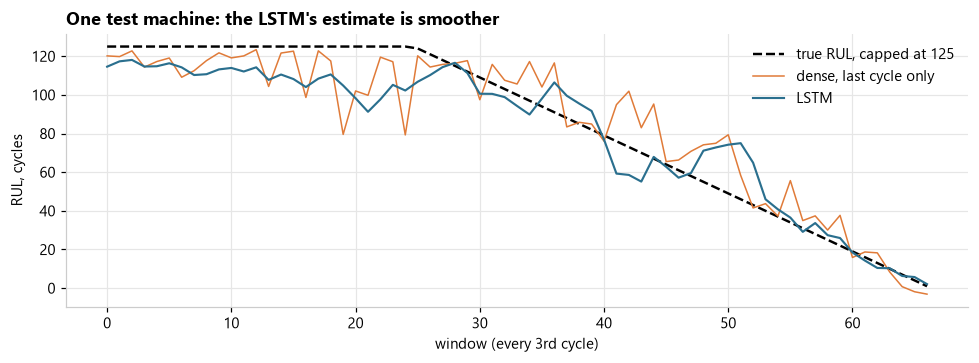

In [29]:
class LSTMRUL(nn.Module):
    def __init__(self, n_sensors=4, hidden=32):
        super().__init__()
        self.lstm = nn.LSTM(n_sensors, hidden, batch_first=True)
        self.out = nn.Linear(hidden, 1)

    def forward(self, x):                       # x: (windows, cycles, sensors)
        h, _ = self.lstm(x)
        return self.out(h[:, -1]).squeeze(1)    # the output after the last cycle


class Flat(nn.Module):
    def __init__(self, n_in, last_only=False):
        super().__init__()
        self.last_only = last_only
        self.net = nn.Sequential(nn.Linear(n_in, 64), nn.ReLU(), nn.Linear(64, 1))

    def forward(self, x):
        x = x[:, -1] if self.last_only else x.flatten(1)
        return self.net(x).squeeze(1)


def fit_rul(net, epochs=15):
    # MSE on the capped, scaled RUL; keeps the epoch with the lowest validation loss
    opt = torch.optim.Adam(net.parameters(), lr=3e-3)
    g = torch.Generator().manual_seed(0)
    best = (np.inf, None)
    for _ in range(epochs):
        net.train()
        for i in torch.randperm(len(Xr_tr), generator=g).split(128):
            opt.zero_grad()
            loss = ((net(Xr_tr[i]) - yr_tr[i]) ** 2).mean()
            loss.backward()
            opt.step()
        net.eval()
        with torch.no_grad():
            v = ((net(Xr_va) - yr_va) ** 2).mean().item()
        if v < best[0]:
            best = (v, copy.deepcopy(net.state_dict()))
    net.load_state_dict(best[1])
    return net


def rmse_cycles(pred):
    return CAP * ((pred - yr_te) ** 2).mean().sqrt().item()


makers = [("dense, last cycle only", lambda: Flat(4, last_only=True)),
          ("dense, whole window", lambda: Flat(WL * 4)),
          ("LSTM", lambda: LSTMRUL())]
models_rul = {}
for name, make in makers:
    torch.manual_seed(0)
    models_rul[name] = fit_rul(make().to(DEVICE))
with torch.no_grad():
    preds = {name: m(Xr_te) for name, m in models_rul.items()}

mean_guess = torch.full_like(yr_te, yr_tr.mean().item())
print(f"{'mean RUL of the training windows':34s} "
      f"test RMSE {rmse_cycles(mean_guess):5.1f} cycles")
for name, p in preds.items():
    print(f"{name:34s} test RMSE {rmse_cycles(p):5.1f} cycles")

m = u_te == 3                                         # the fourth test machine
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(CAP * yr_te.cpu()[m], color="black", ls="--", label="true RUL, capped at 125")
for name, colour, lw in [("dense, last cycle only", ORANGE, 1), ("LSTM", BLUE, 1.4)]:
    ax.plot(CAP * preds[name].cpu()[m], color=colour, lw=lw, label=name)
ax.set(xlabel="window (every 3rd cycle)", ylabel="RUL, cycles",
       title="One test machine: the LSTM's estimate is smoother")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

Test RMSE: the mean 41.3 cycles, the dense network on the last cycle about 17.5, on the whole
window about 17, the LSTM about 15. The last cycle already says a lot, because two sensors follow the wear. The
window adds the trend. The LSTM reads the window in order and carries the trend in its memory,
so one noisy cycle moves its estimate less. The plot shows it on one test machine: the dense
network jumps with every noisy cycle, the LSTM moves smoothly.

Far from failure every model is unsure, and the cap at 125 hides how unsure. Practice 7 does the
same task on the NASA C-MAPSS turbofan data.

---

# Part 16. Attention: every cycle looks at every other

The LSTM reads the window in order and squeezes everything it saw into one memory vector.
**Attention** works differently. Every cycle of the window may look directly at every other
cycle and take what it needs from it. This is the building block of the **transformer**, the
architecture behind today's language models, and it is also used on sensor time series.

## 16.1 The mechanism

The window is a matrix $\mathbf{X}$ of 30 cycles × 4 sensors. Three learned matrices turn every
cycle into three vectors of length $d$: a **query** (what this cycle is looking for), a **key**
(what it offers to others) and a **value** (what it passes on):

$$\mathbf{Q} = \mathbf{X}\mathbf{W}_Q, \qquad \mathbf{K} = \mathbf{X}\mathbf{W}_K, \qquad \mathbf{V} = \mathbf{X}\mathbf{W}_V .$$

How well cycle $i$'s query matches cycle $j$'s key is the dot product $\mathbf{q}_i^\top\mathbf{k}_j$.
A softmax over $j$ turns the matches of row $i$ into weights that are positive and sum to 1, and
the output of cycle $i$ is the weighted average of the values:

$$\mathbf{A} = \operatorname{softmax}\!\Big(\frac{\mathbf{Q}\mathbf{K}^\top}{\sqrt{d}}\Big), \qquad \text{output} = \mathbf{A}\mathbf{V}.$$

So attention is an average whose weights are computed from the data itself. A moving average uses
the same weights for every window; here every window and every cycle gets its own. Below is the
whole mechanism in NumPy, with random matrices in place of learned ones.

In [30]:
def softmax(z):
    z = z - z.max(axis=-1, keepdims=True)    # subtracting the row maximum avoids overflow
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)


def self_attention(X, W_q, W_k, W_v):
    Q = X @ W_q                                    # (cycles, d)
    K = X @ W_k
    V = X @ W_v
    d = Q.shape[1]

    # (cycles, cycles): how well query i fits key j
    scores = Q @ K.T / np.sqrt(d)
    A = softmax(scores)                            # every row sums to 1
    return A @ V, A


rng_a = np.random.default_rng(0)
window = Xr_te[0].cpu().numpy()            # one test window, 30 cycles x 4 sensors
d = 8
W_q, W_k, W_v = (rng_a.normal(0, 1, (4, d)) for _ in range(3))

out, A = self_attention(window, W_q, W_k, W_v)
print("window", window.shape, "-> output", out.shape, "| weights", A.shape)
print("rows of A sum to", A.sum(axis=1)[:3].round(6), "...")
print("weights of the last cycle on the first five:", A[-1, :5].round(3))

window (30, 4) -> output (30, 8) | weights (30, 30)
rows of A sum to [1. 1. 1.] ...
weights of the last cycle on the first five: [0.046 0.025 0.026 0.022 0.038]


**Why divide by $\sqrt{d}$?**

<details><summary>Answer</summary>

If the entries of $\mathbf{q}$ and $\mathbf{k}$ are independent with mean 0 and variance 1, then
$\mathbf{q}^\top\mathbf{k} = \sum_{m=1}^{d} q_m k_m$ is a sum of $d$ terms of variance 1, so its
standard deviation is $\sqrt{d}$. With $d = 512$ the scores spread over tens of units, the softmax
puts almost all the weight on one cycle, and its gradient with respect to the other scores is close
to zero, so training stalls. Dividing by $\sqrt{d}$ brings the scores back to unit spread for any
$d$. The cell below shows it.

</details>

In [31]:
rng_d = np.random.default_rng(1)

for d_try in [4, 64, 512]:
    q = rng_d.normal(0, 1, (1000, d_try))
    k = rng_d.normal(0, 1, (1000, 30, d_try))
    scores = np.einsum("nd,ntd->nt", q, k)          # 1000 queries against 30 keys each

    raw_peak = softmax(scores).max(axis=1).mean()
    scaled_peak = softmax(scores / np.sqrt(d_try)).max(axis=1).mean()
    print(f"d = {d_try:3d}: std of q.k = {scores.std():5.1f};  largest weight of 30, "
          f"unscaled {raw_peak:.2f}, scaled {scaled_peak:.2f}")

d =   4: std of q.k =   2.0;  largest weight of 30, unscaled 0.35, scaled 0.16
d =  64: std of q.k =   8.0;  largest weight of 30, unscaled 0.82, scaled 0.17


d = 512: std of q.k =  22.7;  largest weight of 30, unscaled 0.94, scaled 0.17


## 16.2 A small attention model for the RUL

The model below is one transformer layer, the smallest that still has all its parts:

- a linear layer turns the 4 sensors of every cycle into a vector of $d = 32$;
- a learned **position** vector is added to every cycle. Attention by itself treats the window as a
  set: shuffle the cycles and the weights shuffle with them. The position vectors tell the model
  which cycle came when;
- one attention block, then a small dense network applied to every cycle, each with a residual
  connection and layer normalisation;
- the output of the last cycle goes to a linear layer that gives the RUL.

PyTorch's `nn.MultiheadAttention` does what `self_attention` above does, with learned matrices.
It is trained with the same `fit_rul` as the LSTM. Part 6 showed that one training run is one
draw, so both models train with three seeds.

In [32]:
class AttentionRUL(nn.Module):
    def __init__(self, n_sensors=4, d=32):
        super().__init__()
        self.embed = nn.Linear(n_sensors, d)
        self.position = nn.Parameter(torch.zeros(WL, d))
        self.attention = nn.MultiheadAttention(d, num_heads=1, batch_first=True)
        self.norm1 = nn.LayerNorm(d)
        self.dense = nn.Sequential(
            nn.Linear(d, 64),
            nn.ReLU(),
            nn.Linear(64, d),
        )
        self.norm2 = nn.LayerNorm(d)
        self.out = nn.Linear(d, 1)

    def forward(self, x, return_weights=False):     # x: (windows, cycles, sensors)
        z = self.embed(x) + self.position

        attended, weights = self.attention(z, z, z)
        z = self.norm1(z + attended)
        z = self.norm2(z + self.dense(z))

        rul = self.out(z[:, -1]).squeeze(1)         # the output of the last cycle
        if return_weights:
            return rul, weights
        return rul


rows = []
for name, make in [("LSTM", LSTMRUL), ("attention", AttentionRUL)]:
    for seed in range(3):
        torch.manual_seed(seed)
        net = fit_rul(make().to(DEVICE))
        with torch.no_grad():
            rmse = rmse_cycles(net(Xr_te))
        n_weights = sum(p.numel() for p in net.parameters())
        rows.append({"model": name, "seed": seed, "weights": n_weights,
                     "test RMSE": rmse})

attention_net = net                          # the last one trained: attention, seed 2
results_rul = pd.DataFrame(rows)
summary = results_rul.groupby("model")["test RMSE"].agg(["mean", "min", "max"])
by_seed_rul = results_rul.pivot(index="model", columns="seed", values="test RMSE")
print(by_seed_rul.round(1).to_string())
print()
print(summary.round(1).to_string())

seed           0      1      2
model                         
LSTM      15.000 15.400 15.800
attention 15.600 15.300 14.900

            mean    min    max
model                         
LSTM      15.400 15.000 15.800
attention 15.300 14.900 15.600


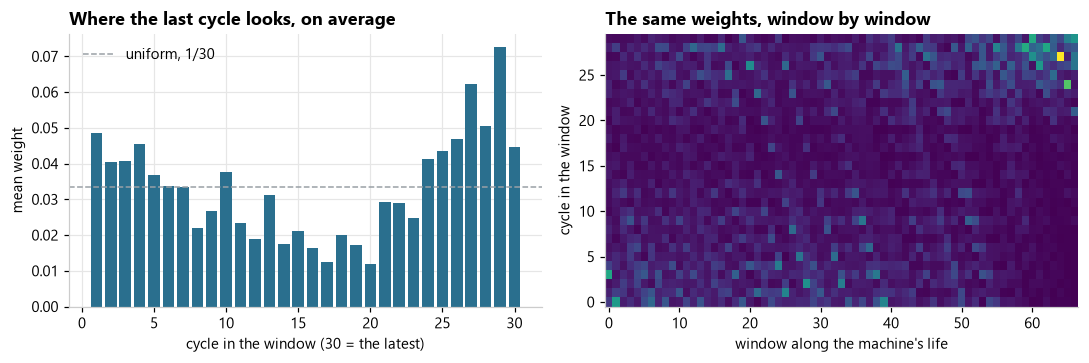

weight on the 10 latest cycles: 0.44 (uniform: 0.33)


In [33]:
with torch.no_grad():
    _, weights = attention_net(Xr_te, return_weights=True)

last_query = weights[:, -1].cpu().numpy()    # (windows, 30): where the last cycle looks
mean_weight = last_query.mean(axis=0)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))

ax[0].bar(np.arange(1, WL + 1), mean_weight, color=BLUE)
ax[0].axhline(1 / WL, color=GREY, ls="--", lw=1, label="uniform, 1/30")
ax[0].set(xlabel="cycle in the window (30 = the latest)", ylabel="mean weight",
          title="Where the last cycle looks, on average")
ax[0].legend(loc="upper left")

one_machine = u_te == 3                              # the test machine of Part 15
ax[1].imshow(last_query[one_machine].T, aspect="auto", origin="lower", cmap="viridis")
ax[1].grid(False)
ax[1].set(xlabel="window along the machine's life", ylabel="cycle in the window",
          title="The same weights, window by window")

fig.tight_layout()
plt.show()

print(f"weight on the 10 latest cycles: {mean_weight[-10:].sum():.2f} (uniform: 0.33)")

The two models tie. Over three seeds the LSTM's test RMSE runs from 15.0 to 15.8 cycles, the
attention model's from 14.9 to 15.6, and the ranges overlap. On windows of 30 cycles and 4 sensors
there is little for attention to win: the LSTM's memory easily spans 30 steps. Transformers pay
off on long histories, many sensors and much more data, and that is where the time-series models
in the further reading are used.

The weights show what the model learned to look at. The last cycle puts more weight on the latest
cycles, 0.44 on the ten newest against 0.33 for a uniform average, and also more on the oldest
few. A trend is a difference between the end and the start of the window, so both ends matter.
The right panel shows the same weights along one machine's life. Near the end of life they
concentrate on the latest cycles, where the wear now changes fastest.

---

## Questions to think about

1. The neuron of Part 1 and `LogisticRegression` gave the same weights. What would have to
   change in the neuron to make it something a logistic regression cannot be?
2. In Part 2 the hidden layer had 16 neurons. Roughly how many bends does the curve need for the
   power band? Would 2 hidden neurons be enough in principle?
3. In Part 3 the validation loss went up while the train loss went down. Name two things other
   than early stopping that would slow that down.
4. Early stopping chose the epoch on validation. Why is the validation AP of the restored network
   a little optimistic?
5. The forest won Part 5. Name a situation in a plant where you would still choose the network.
6. The agent of Part 7 sees only the room temperature. The room needs more heat at night than at
   noon. Why does the agent manage anyway, and what would the time of day add to the table?
7. Drop the comfort term from the reward. What policy will the table learn? And without the
   energy term?
8. The thermostat has a hysteresis band of 1 °C, the agent switches every 5 minutes if it wants.
   What would you add to the reward to protect the heater's contactor?
9. In Part 10 the frozen stretch was found because real readings are noisy. Which sensor in a
   plant could be legitimately constant for ten minutes, and how would you tell it from a stuck
   one?
10. The Kalman filter used $q = 10^{-5}$. What happens to its lag and to its noise if $q$ is ten
    times larger? Ten times smaller?
11. The autoencoder's threshold was the 99.5th percentile of the training error. Why do the
    alarms after training come more often than 0.5 %?
12. The CNN never saw the defect frequencies 3.58 and 5.42. What could it have used instead?
13. Why cap the RUL at 125 cycles? What would the models learn without the cap?

**Next.** **Practice 4** is one notebook in two sections: the network of Parts 3–6 on vibration
from a test rig with ten bearing states (Section 1); Parts 13, 14 and 12 on the raw vibration of
the same rig (Section 2).

## Further reading

- **Reinforcement learning beyond the table.** When the state is too large for a table, the
  Q-values come from a network. The Deep Q-Network (Mnih et al., *Nature*, 2015) made this stable
  with a replay buffer and a frozen target network. Monte Carlo methods learn from whole episodes
  instead of single steps, and policy-gradient methods such as PPO learn the policy directly; PPO
  is the usual choice for continuous actions such as a valve position. Sutton and Barto,
  *Reinforcement Learning: An Introduction* (2nd ed., 2018), covers all of them.
- **Sequence models.** The GRU is a lighter LSTM with two gates instead of three. Temporal
  convolutional networks read a window with dilated 1-D convolutions and train faster than
  recurrent ones. For long sensor histories there are transformers built for time series, which
  cut the series into patches of cycles and attend over the patches.